In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from shapely.geometry import Point, LineString, Polygon, MultiPoint, mapping
import numpy as np
import matplotlib.cm as cm
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm
import plotly.express as px

In [2]:
# for the langoid CSV file 
df = pd.read_csv("glottolog_languoid.csv/languoid.csv") 
df.head() 

,id,family_id,parent_id,name,bookkeeping,level,latitude,longitude,iso639P3code,description,markup_description,child_family_count,child_language_count,child_dialect_count,country_ids
0,3adt1234,afro1255,nort3292,3Ad-Tekles,False,dialect,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN
1,aala1237,aust1307,ramo1244,Aalawa,False,dialect,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN
2,aant1238,nucl1709,nort2920,Aantantara,False,dialect,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN
3,aari1238,sout2845,ahkk1235,Aari-Gayil,False,family,NaN,NaN,aiz,NaN,NaN,0,2,0,NaN
4,aari1239,sout2845,aari1238,Aari,False,language,5.95034,36.5721,aiw,NaN,NaN,0,0,0,ET


In [3]:
df = pd.read_csv("dravidian-mother-tongues-main-n-level.csv")
df = df.dropna()
df

,Mother tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F
0,Malayalam,34776533,16681977,18094556,17355542,8339365,9016177,17420991,8342612,9078379
1,Tamil,68888839,34531580,34357259,35530671,17829882,17700789,33358168,16701698,16656470
2,Telugu,80912459,40549767,40362692,53738513,26918237,26820276,27173946,13631530,13542416
3,Kannada,43506272,22014001,21492271,30614889,15462374,15152515,12891383,6551627,6339756
4,Tulu,1841963,899059,942904,1081821,525977,555844,760142,373082,387060


In [4]:
df.columns

Index(['Mother tongue', 'Total_P', 'Total_M', 'Total_F', 'Rural_P', 'Rural_M',
       'Rural_F', 'Urban_P', 'Urban_M', 'Urban_F'],
      dtype='str')

In [5]:
### Nation-level Plotting

In [6]:
### Total Mother Tongue Speakers

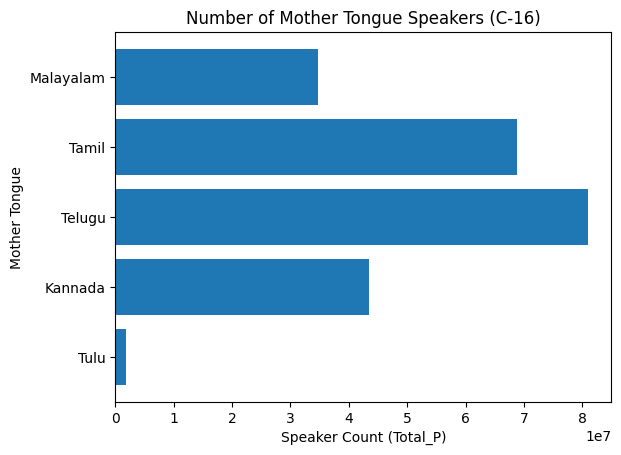

In [7]:
fig, ax = plt.subplots()

# Example data
ax.barh(
    df["Mother tongue"],
    df["Total_P"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Total_P)")
ax.set_title("Number of Mother Tongue Speakers (C-16)")
ax.invert_yaxis()

plt.show()

In [8]:
# for the langoid CSV file 
df = pd.read_csv("glottolog_languoid.csv/languoid.csv") 
df.head() 

,id,family_id,parent_id,name,bookkeeping,level,latitude,longitude,iso639P3code,description,markup_description,child_family_count,child_language_count,child_dialect_count,country_ids
0,3adt1234,afro1255,nort3292,3Ad-Tekles,False,dialect,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN
1,aala1237,aust1307,ramo1244,Aalawa,False,dialect,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN
2,aant1238,nucl1709,nort2920,Aantantara,False,dialect,NaN,NaN,NaN,NaN,NaN,0,0,0,NaN
3,aari1238,sout2845,ahkk1235,Aari-Gayil,False,family,NaN,NaN,aiz,NaN,NaN,0,2,0,NaN
4,aari1239,sout2845,aari1238,Aari,False,language,5.95034,36.5721,aiw,NaN,NaN,0,0,0,ET


In [9]:
df.columns

Index(['id', 'family_id', 'parent_id', 'name', 'bookkeeping', 'level',
       'latitude', 'longitude', 'iso639P3code', 'description',
       'markup_description', 'child_family_count', 'child_language_count',
       'child_dialect_count', 'country_ids'],
      dtype='str')

In [10]:
tamil = df[df["name"] == "Tamil"]
tamil

,id,family_id,parent_id,name,bookkeeping,level,latitude,longitude,iso639P3code,description,markup_description,child_family_count,child_language_count,child_dialect_count,country_ids
22917,tami1289,drav1251,tami1300,Tamil,False,language,10.520219,78.825989,tam,NaN,NaN,0,0,18,IN LK


In [11]:
malayalam = df[df["name"] == "Malayalam"]
malayalam

,id,family_id,parent_id,name,bookkeeping,level,latitude,longitude,iso639P3code,description,markup_description,child_family_count,child_language_count,child_dialect_count,country_ids
13316,mala1464,drav1251,mala1541,Malayalam,False,language,9.59208,76.7651,mal,NaN,NaN,0,0,13,IN


In [12]:
tamil_longitude_val = tamil["longitude"].iloc[0]
tamil_latitude_val = tamil["latitude"].iloc[0]
# created a geometric object in coordinate space 
tamil_point = Point(tamil_longitude_val, tamil_latitude_val)

In [13]:
type(tamil_point)

shapely.geometry.point.Point

In [14]:
## need to put the point into a geodataframe 
tamil_gdf = gpd.GeoDataFrame(
    {
        "name": ["Tamil"],
        "iso": ["tam"],
        "geometry": [tamil_point]
    },
    crs="EPSG:4326"
)

In [15]:
### NOW TO GET A POLYGON LAYER (INDIA) 
india_states = gpd.read_file("gadm41_IND_shp/gadm41_IND_1.shp") 
india_states.head()

,GID_1,GID_0,COUNTRY,NAME_1,VARNAME_1,NL_NAME_1,TYPE_1,ENGTYPE_1,CC_1,HASC_1,ISO_1,geometry
0,IND.1_1,IND,India,Andaman and Nicobar,Andaman & Nicobar Islands|Andama,NA,Union Territor,Union Territory,NA,IN.AN,NA,"MULTIPOLYGON (((93.79078 6.85139, 93.79092 6.8..."
1,IND.2_1,IND,India,Andhra Pradesh,NA,NA,State,State,NA,IN.AP,IN-AP,"MULTIPOLYGON (((78.73952 13.04549, 78.73218 13..."
2,IND.3_1,IND,India,Arunachal Pradesh,Agence de la Frontière du Nord-E,NA,State,State,NA,IN.AR,IN-AR,"POLYGON ((95.3683 27.10736, 95.37366 27.108, 9..."
3,Z07.3_1,Z07,India,Arunachal Pradesh,Agence de la Frontière du Nord-E,NA,State,State,NA,IN.AR,NA,"POLYGON ((94.19125 27.49632, 94.1869 27.49081,..."
4,IND.4_1,IND,India,Assam,NA,NA,State,State,NA,IN.AS,IN-AS,"POLYGON ((92.7545 24.50112, 92.75133 24.49437,..."


## State Level Plotting

In [16]:
### State Level Graphs
state_df = pd.read_csv("dravidian-mother-tongues-main-state-level.csv")
state_df

,State_UT,Mother Tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F,Unnamed: 11,Unnamed: 12,Unnamed: 13
0,Kerala,Malayalam,32393324,15482417,16910907,16848670,8082073,8766597,15544654,7400344,8144310,NaN,NaN,NaN
1,Karnataka,Malayalam,745903,374572,371331,312494,155400,157094,433409,219172,214237,NaN,NaN,NaN
2,Tamil Nadu,Malayalam,718977,347788,371189,104745,51089,53656,614232,296699,317533,NaN,NaN,NaN
3,Maharashtra,Malayalam,365140,187005,178135,14444,7890,6554,350696,179115,171581,NaN,NaN,NaN
4,NCT of Delhi,Malayalam,87718,44258,43460,147,68,79,87571,44190,43381,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135,Daman and Diu,Telugu,319,183,136,12,7,5,307,176,131,NaN,NaN,NaN
136,Dadra and Nagar Haveli,Telugu,770,406,364,76,37,39,694,369,325,NaN,NaN,NaN
137,Chandigarh,Telugu,1332,789,543,22,10,12,1310,779,531,NaN,NaN,NaN
138,Andaman and Nicobar,Telugu,50394,26208,24186,17431,9055,8376,32963,17153,15810,NaN,NaN,NaN


In [17]:
india_states["NAME_1"].unique()

<StringArray>
[   'Andaman and Nicobar',         'Andhra Pradesh',      'Arunachal Pradesh',
                  'Assam',                  'Bihar',             'Chandigarh',
           'Chhattisgarh', 'Dadra and Nagar Haveli',          'Daman and Diu',
                    'Goa',                'Gujarat',                'Haryana',
       'Himachal Pradesh',      'Jammu and Kashmir',              'Jharkhand',
              'Karnataka',                 'Kerala',            'Lakshadweep',
         'Madhya Pradesh',            'Maharashtra',                'Manipur',
              'Meghalaya',                'Mizoram',               'Nagaland',
           'NCT of Delhi',                 'Odisha',             'Puducherry',
                 'Punjab',              'Rajasthan',                 'Sikkim',
             'Tamil Nadu',              'Telangana',                'Tripura',
          'Uttar Pradesh',            'Uttarakhand',            'West Bengal']
Length: 36, dtype: str

In [18]:
india_states[["NAME_1", "geometry"]].head()

,NAME_1,geometry
0,Andaman and Nicobar,"MULTIPOLYGON (((93.79078 6.85139, 93.79092 6.8..."
1,Andhra Pradesh,"MULTIPOLYGON (((78.73952 13.04549, 78.73218 13..."
2,Arunachal Pradesh,"POLYGON ((95.3683 27.10736, 95.37366 27.108, 9..."
3,Arunachal Pradesh,"POLYGON ((94.19125 27.49632, 94.1869 27.49081,..."
4,Assam,"POLYGON ((92.7545 24.50112, 92.75133 24.49437,..."


### Malayalam 

In [19]:
malayalam_df = state_df[state_df["Mother Tongue"] == "Malayalam"]
malayalam_df

,State_UT,Mother Tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F,Unnamed: 11,Unnamed: 12,Unnamed: 13
0,Kerala,Malayalam,32393324,15482417,16910907,16848670,8082073,8766597,15544654,7400344,8144310,NaN,NaN,NaN
1,Karnataka,Malayalam,745903,374572,371331,312494,155400,157094,433409,219172,214237,NaN,NaN,NaN
2,Tamil Nadu,Malayalam,718977,347788,371189,104745,51089,53656,614232,296699,317533,NaN,NaN,NaN
3,Maharashtra,Malayalam,365140,187005,178135,14444,7890,6554,350696,179115,171581,NaN,NaN,NaN
4,NCT of Delhi,Malayalam,87718,44258,43460,147,68,79,87571,44190,43381,NaN,NaN,NaN
5,Andhra Pradesh,Malayalam,61108,29648,31460,8378,3814,4564,52730,25834,26896,NaN,NaN,NaN
6,Goa,Malayalam,12975,7146,5829,1778,959,819,11197,6187,5010,NaN,NaN,NaN
7,Gujarat,Malayalam,64969,34194,30775,3965,2347,1618,61004,31847,29157,NaN,NaN,NaN
8,Rajasthan,Malayalam,22707,11948,10759,5266,2909,2357,17441,9039,8402,NaN,NaN,NaN
9,Chhattisgarh,Malayalam,23365,11731,11634,1510,813,697,21855,10918,10937,NaN,NaN,NaN


In [20]:
## Plotting Total_P on Choropleth map

In [21]:
## Merging Malayalam data with india_states 
mal_map = india_states.merge(malayalam_df, left_on="NAME_1", right_on="State_UT", how="left")
mal_map.head()

,GID_1,GID_0,COUNTRY,NAME_1,VARNAME_1,NL_NAME_1,TYPE_1,ENGTYPE_1,CC_1,HASC_1,...,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F,Unnamed: 11,Unnamed: 12,Unnamed: 13
0,IND.1_1,IND,India,Andaman and Nicobar,Andaman & Nicobar Islands|Andama,NA,Union Territor,Union Territory,NA,IN.AN,...,13479.0,14440.0,7397.0,7043.0,13030.0,6594.0,6436.0,NaN,NaN,NaN
1,IND.2_1,IND,India,Andhra Pradesh,NA,NA,State,State,NA,IN.AP,...,31460.0,8378.0,3814.0,4564.0,52730.0,25834.0,26896.0,NaN,NaN,NaN
2,IND.3_1,IND,India,Arunachal Pradesh,Agence de la Frontière du Nord-E,NA,State,State,NA,IN.AR,...,1339.0,1552.0,1148.0,404.0,2460.0,1525.0,935.0,NaN,NaN,NaN
3,Z07.3_1,Z07,India,Arunachal Pradesh,Agence de la Frontière du Nord-E,NA,State,State,NA,IN.AR,...,1339.0,1552.0,1148.0,404.0,2460.0,1525.0,935.0,NaN,NaN,NaN
4,IND.4_1,IND,India,Assam,NA,NA,State,State,NA,IN.AS,...,1822.0,3837.0,2797.0,1040.0,1922.0,1140.0,782.0,NaN,NaN,NaN


In [22]:
mal_map_slim = mal_map[["NAME_1", "Mother Tongue", "Total_P"]].dropna()
mal_map_slim

,NAME_1,Mother Tongue,Total_P
0,Andaman and Nicobar,Malayalam,27470.0
1,Andhra Pradesh,Malayalam,61108.0
2,Arunachal Pradesh,Malayalam,4012.0
3,Arunachal Pradesh,Malayalam,4012.0
4,Assam,Malayalam,5759.0
5,Bihar,Malayalam,899.0
6,Chandigarh,Malayalam,1974.0
7,Chhattisgarh,Malayalam,23365.0
8,Dadra and Nagar Haveli,Malayalam,2168.0
9,Daman and Diu,Malayalam,1224.0


In [23]:
# The rows GADM has for Maharashtra
mal_map[mal_map["NAME_1"].str.contains("Maharashtra", case=False, na=False)][
    ["NAME_1", "State_UT", "Mother Tongue", "Total_P", "geometry"]
]

# Seeing if NAME_1 values have ANY null Total_P after the merge?
mal_map[mal_map["Total_P"].isna()]["NAME_1"].value_counts()

NAME_1
Telangana    1
Name: count, dtype: int64

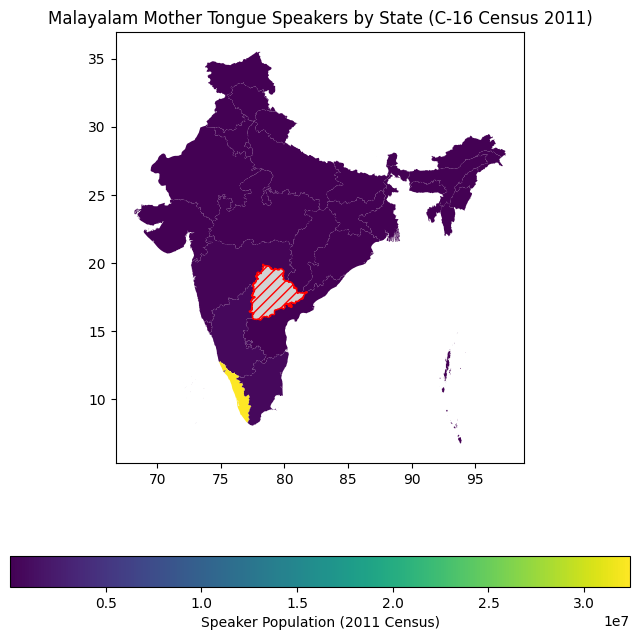

In [24]:
fig, ax = plt.subplots(figsize=(8,8))

mal_map.plot(
    ax=ax,
    column="Total_P",
    legend=True,
      missing_kwds={
        "color": "lightgrey",
        "edgecolor": "red",
        "hatch": "///",
        "label": "Missing values",
    },
    legend_kwds={"label": "Speaker Population (2011 Census)", "orientation": "horizontal"}
);

ax.set_title(
    "Malayalam Mother Tongue Speakers by State (C-16 Census 2011)", 
    fontsize=12
);

In [25]:
## Not Including Kerala 

mal_map_outside = mal_map[mal_map["NAME_1"] != "Kerala"]
mal_map_outside[["NAME_1", "Mother Tongue", "Total_P"]].dropna()

,NAME_1,Mother Tongue,Total_P
0,Andaman and Nicobar,Malayalam,27470.0
1,Andhra Pradesh,Malayalam,61108.0
2,Arunachal Pradesh,Malayalam,4012.0
3,Arunachal Pradesh,Malayalam,4012.0
4,Assam,Malayalam,5759.0
5,Bihar,Malayalam,899.0
6,Chandigarh,Malayalam,1974.0
7,Chhattisgarh,Malayalam,23365.0
8,Dadra and Nagar Haveli,Malayalam,2168.0
9,Daman and Diu,Malayalam,1224.0


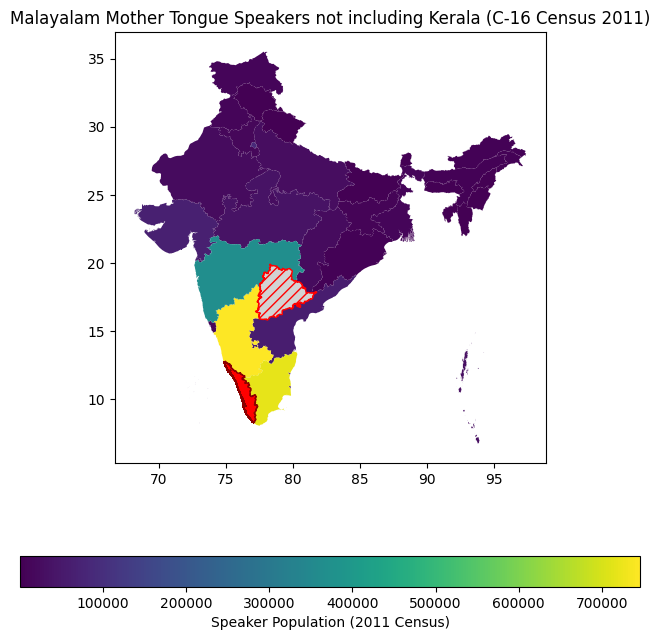

In [26]:
fig, ax = plt.subplots(figsize=(8,8))

mal_map_outside.plot(
    ax=ax,
    column="Total_P",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "red",
        "hatch": "///",
        "label": "Missing values",
    },
    legend_kwds={"label": "Speaker Population (2011 Census)", "orientation": "horizontal"}
);


## Adding Kerala to the map as a red element separate from Total_P
kerala_geom = mal_map[mal_map["NAME_1"] == "Kerala"]
kerala_geom.plot(
    ax=ax, 
    color="red", 
    edgecolor="darkred",
    linewidth=1, 
    label="Kerala (native state, excluded from scale)"
)

ax.set_title(
    "Malayalam Mother Tongue Speakers not including Kerala (C-16 Census 2011)", 
    fontsize=12
);

### Tamil 

In [27]:
tamil_df = state_df[state_df["Mother Tongue"] == "Tamil"]
tamil_df

,State_UT,Mother Tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F,Unnamed: 11,Unnamed: 12,Unnamed: 13
35,Kerala,Tamil,498938,257186,241752,342679,174405,168274,156259,82781,73478,NaN,NaN,NaN
36,Karnataka,Tamil,2101032,1062389,1038643,328485,167600,160885,1772547,894789,877758,NaN,NaN,NaN
37,Tamil Nadu,Tamil,63743847,31913539,31830308,34087554,17096202,16991352,29656293,14817337,14838956,NaN,NaN,NaN
38,Maharashtra,Tamil,484726,250731,233995,11104,6154,4950,473622,244577,229045,NaN,NaN,NaN
39,NCT of Delhi,Tamil,82665,42661,40004,106,62,44,82559,42599,39960,NaN,NaN,NaN
40,Andhra Pradesh,Tamil,625546,313271,312275,318459,158772,159687,307087,154499,152588,NaN,NaN,NaN
41,Goa,Tamil,6939,3926,3013,1284,655,629,5655,3271,2384,NaN,NaN,NaN
42,Gujarat,Tamil,39763,21576,18187,2449,1460,989,37314,20116,17198,NaN,NaN,NaN
43,Rajasthan,Tamil,3905,2451,1454,1291,830,461,2614,1621,993,NaN,NaN,NaN
44,Chhattisgarh,Tamil,10284,5584,4700,1261,834,427,9023,4750,4273,NaN,NaN,NaN


In [28]:
## Plotting Total_P on Choropleth map
## Merging Tamil data with india_states 
tamil_map = india_states.merge(tamil_df, left_on="NAME_1", right_on="State_UT", how="left")
tamil_map.head()

,GID_1,GID_0,COUNTRY,NAME_1,VARNAME_1,NL_NAME_1,TYPE_1,ENGTYPE_1,CC_1,HASC_1,...,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F,Unnamed: 11,Unnamed: 12,Unnamed: 13
0,IND.1_1,IND,India,Andaman and Nicobar,Andaman & Nicobar Islands|Andama,NA,Union Territor,Union Territory,NA,IN.AN,...,26965.0,22653.0,12181.0,10472.0,35177.0,18684.0,16493.0,NaN,NaN,NaN
1,IND.2_1,IND,India,Andhra Pradesh,NA,NA,State,State,NA,IN.AP,...,312275.0,318459.0,158772.0,159687.0,307087.0,154499.0,152588.0,NaN,NaN,NaN
2,IND.3_1,IND,India,Arunachal Pradesh,Agence de la Frontière du Nord-E,NA,State,State,NA,IN.AR,...,195.0,814.0,708.0,106.0,431.0,342.0,89.0,NaN,NaN,NaN
3,Z07.3_1,Z07,India,Arunachal Pradesh,Agence de la Frontière du Nord-E,NA,State,State,NA,IN.AR,...,195.0,814.0,708.0,106.0,431.0,342.0,89.0,NaN,NaN,NaN
4,IND.4_1,IND,India,Assam,NA,NA,State,State,NA,IN.AS,...,978.0,3719.0,3208.0,511.0,1477.0,1010.0,467.0,NaN,NaN,NaN


In [29]:
tam_map_slim = tamil_map[["NAME_1", "Mother Tongue", "Total_P"]].dropna()
tam_map_slim

,NAME_1,Mother Tongue,Total_P
0,Andaman and Nicobar,Tamil,57830.0
1,Andhra Pradesh,Tamil,625546.0
2,Arunachal Pradesh,Tamil,1245.0
3,Arunachal Pradesh,Tamil,1245.0
4,Assam,Tamil,5196.0
5,Bihar,Tamil,975.0
6,Chandigarh,Tamil,5579.0
7,Chhattisgarh,Tamil,10284.0
8,Dadra and Nagar Haveli,Tamil,739.0
9,Daman and Diu,Tamil,319.0


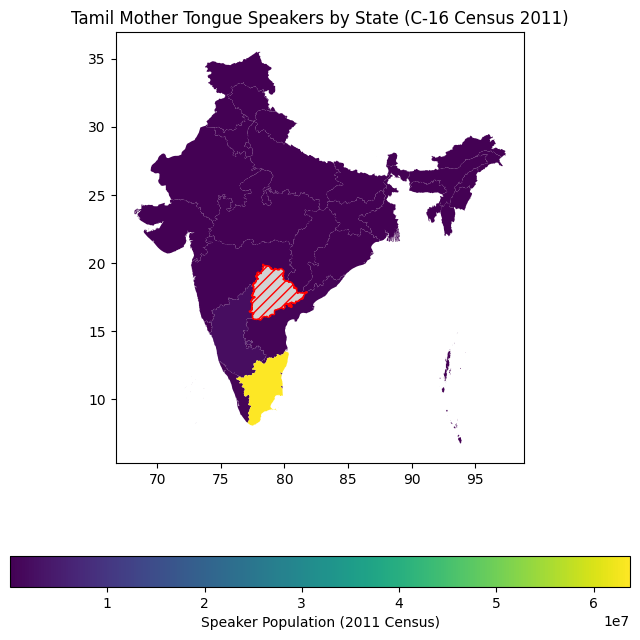

In [30]:
fig, ax = plt.subplots(figsize=(8,8))

tamil_map.plot(
    ax=ax,
    column="Total_P",
    legend=True,
      missing_kwds={
        "color": "lightgrey",
        "edgecolor": "red",
        "hatch": "///",
        "label": "Missing values",
    },
    legend_kwds={"label": "Speaker Population (2011 Census)", "orientation": "horizontal"}
);

ax.set_title(
    "Tamil Mother Tongue Speakers by State (C-16 Census 2011)", 
    fontsize=12
);

In [31]:
## Not including Tamil Nadu


tam_map_outside = tamil_map[tamil_map["NAME_1"] != "Tamil Nadu"]
tam_map_outside[["NAME_1", "Mother Tongue", "Total_P"]].dropna()

,NAME_1,Mother Tongue,Total_P
0,Andaman and Nicobar,Tamil,57830.0
1,Andhra Pradesh,Tamil,625546.0
2,Arunachal Pradesh,Tamil,1245.0
3,Arunachal Pradesh,Tamil,1245.0
4,Assam,Tamil,5196.0
5,Bihar,Tamil,975.0
6,Chandigarh,Tamil,5579.0
7,Chhattisgarh,Tamil,10284.0
8,Dadra and Nagar Haveli,Tamil,739.0
9,Daman and Diu,Tamil,319.0


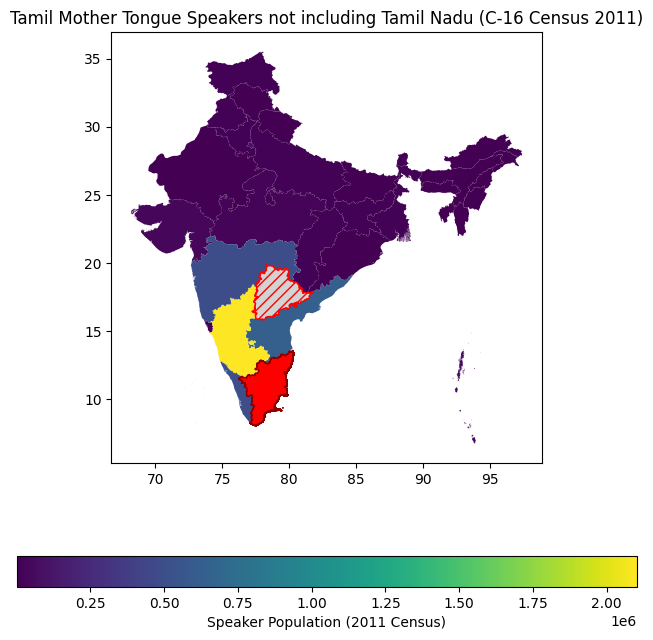

In [32]:
fig, ax = plt.subplots(figsize=(8,8))

tam_map_outside.plot(
    ax=ax,
    column="Total_P",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "red",
        "hatch": "///",
        "label": "Missing values",
    },
    legend_kwds={"label": "Speaker Population (2011 Census)", "orientation": "horizontal"}
);

## Adding Tamil Nadu to the map as a red element separate from Total_P
tamil_nadu_geom = mal_map[mal_map["NAME_1"] == "Tamil Nadu"]
tamil_nadu_geom.plot(
    ax=ax, 
    color="red", 
    edgecolor="darkred",
    linewidth=1, 
    label="Tamil (native state, excluded from scale)"
)


ax.set_title(
    "Tamil Mother Tongue Speakers not including Tamil Nadu (C-16 Census 2011)", 
    fontsize=12
);

In [33]:
### Telugu 

In [34]:
telugu_df = state_df[state_df["Mother Tongue"] == "Telugu"]
telugu_df

,State_UT,Mother Tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F,Unnamed: 11,Unnamed: 12,Unnamed: 13
105,Kerala,Telugu,50394,26208,24186,17431,9055,8376,32963,17153,15810,NaN,NaN,NaN
106,Karnataka,Telugu,3565618,1796969,1768649,1616012,808160,807852,1949606,988809,960797,NaN,NaN,NaN
107,Tamil Nadu,Telugu,4234216,2117945,2116271,1973842,991195,982647,2260374,1126750,1133624,NaN,NaN,NaN
108,Maharashtra,Telugu,1118694,568180,550514,311977,157266,154711,806717,410914,395803,NaN,NaN,NaN
109,NCT of Delhi,Telugu,25882,13682,12200,105,51,54,25777,13631,12146,NaN,NaN,NaN
110,Andhra Pradesh,Telugu,70662838,35382930,35279908,49347283,24714317,24632966,21315555,10668613,10646942,NaN,NaN,NaN
111,Goa,Telugu,10954,6007,4947,2221,1133,1088,8733,4874,3859,NaN,NaN,NaN
112,Gujarat,Telugu,72305,38686,33619,3869,2237,1632,68436,36449,31987,NaN,NaN,NaN
113,Rajasthan,Telugu,8298,5263,3035,2521,1641,880,5777,3622,2155,NaN,NaN,NaN
114,Chhattisgarh,Telugu,1332,789,543,22,10,12,1310,779,531,NaN,NaN,NaN


In [35]:
## Plotting Total_P on Choropleth map
## Merging Telugu data with india_states 
telugu_map = india_states.merge(telugu_df, left_on="NAME_1", right_on="State_UT", how="left")
telugu_map.head()

,GID_1,GID_0,COUNTRY,NAME_1,VARNAME_1,NL_NAME_1,TYPE_1,ENGTYPE_1,CC_1,HASC_1,...,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F,Unnamed: 11,Unnamed: 12,Unnamed: 13
0,IND.1_1,IND,India,Andaman and Nicobar,Andaman & Nicobar Islands|Andama,NA,Union Territor,Union Territory,NA,IN.AN,...,24186.0,17431.0,9055.0,8376.0,32963.0,17153.0,15810.0,NaN,NaN,NaN
1,IND.2_1,IND,India,Andhra Pradesh,NA,NA,State,State,NA,IN.AP,...,35279908.0,49347283.0,24714317.0,24632966.0,21315555.0,10668613.0,10646942.0,NaN,NaN,NaN
2,IND.3_1,IND,India,Arunachal Pradesh,Agence de la Frontière du Nord-E,NA,State,State,NA,IN.AR,...,428.0,936.0,729.0,207.0,696.0,475.0,221.0,NaN,NaN,NaN
3,Z07.3_1,Z07,India,Arunachal Pradesh,Agence de la Frontière du Nord-E,NA,State,State,NA,IN.AR,...,428.0,936.0,729.0,207.0,696.0,475.0,221.0,NaN,NaN,NaN
4,IND.4_1,IND,India,Assam,NA,NA,State,State,NA,IN.AS,...,11948.0,11777.0,7092.0,4685.0,14762.0,7499.0,7263.0,NaN,NaN,NaN


In [36]:
telugu_map[["NAME_1", "Mother Tongue", "Total_P"]].dropna()

,NAME_1,Mother Tongue,Total_P
0,Andaman and Nicobar,Telugu,50394.0
1,Andhra Pradesh,Telugu,70662838.0
2,Arunachal Pradesh,Telugu,1632.0
3,Arunachal Pradesh,Telugu,1632.0
4,Assam,Telugu,26539.0
5,Bihar,Telugu,1212.0
6,Chandigarh,Telugu,1332.0
7,Chhattisgarh,Telugu,1332.0
8,Dadra and Nagar Haveli,Telugu,770.0
9,Daman and Diu,Telugu,319.0


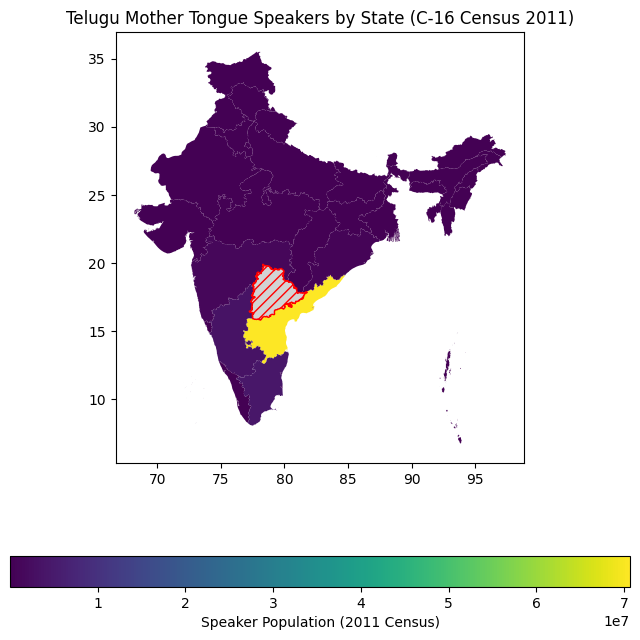

In [37]:
fig, ax = plt.subplots(figsize=(8,8))

telugu_map.plot(
    ax=ax,
    column="Total_P",
    legend=True,
     missing_kwds={
        "color": "lightgrey",
        "edgecolor": "red",
        "hatch": "///",
        "label": "Missing values",
    },
    legend_kwds={"label": "Speaker Population (2011 Census)", "orientation": "horizontal"}
);


ax.set_title(
    "Telugu Mother Tongue Speakers by State (C-16 Census 2011)", 
    fontsize=12
);

In [38]:
### Not including Andhra Pradesh


telugu_map_outside = telugu_map[telugu_map["NAME_1"] != "Andhra Pradesh"]
telugu_map_outside[["NAME_1", "Mother Tongue", "Total_P"]].dropna()

,NAME_1,Mother Tongue,Total_P
0,Andaman and Nicobar,Telugu,50394.0
2,Arunachal Pradesh,Telugu,1632.0
3,Arunachal Pradesh,Telugu,1632.0
4,Assam,Telugu,26539.0
5,Bihar,Telugu,1212.0
6,Chandigarh,Telugu,1332.0
7,Chhattisgarh,Telugu,1332.0
8,Dadra and Nagar Haveli,Telugu,770.0
9,Daman and Diu,Telugu,319.0
10,Goa,Telugu,10954.0


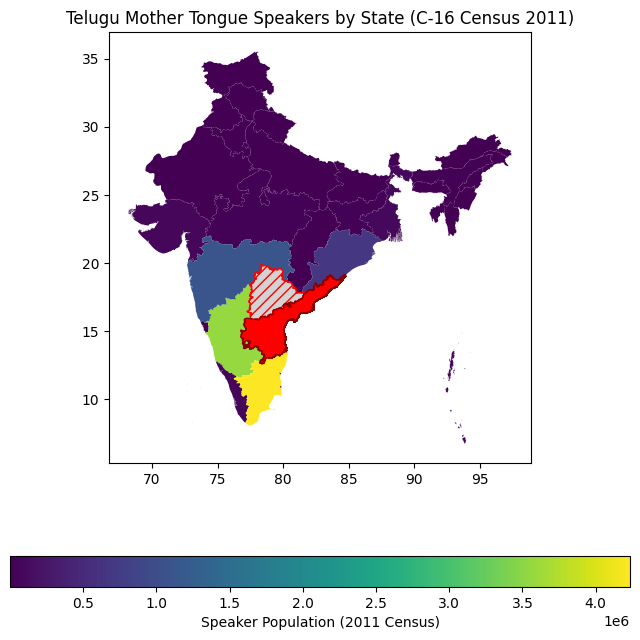

In [39]:
fig, ax = plt.subplots(figsize=(8,8))

telugu_map_outside.plot(
    ax=ax,
    column="Total_P",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "red",
        "hatch": "///",
        "label": "Missing values",
    },
    legend_kwds={"label": "Speaker Population (2011 Census)", "orientation": "horizontal"}
);


## Adding Andhra Pradesh to the map as a red element separate from Total_P
andhra_geom = mal_map[mal_map["NAME_1"] == "Andhra Pradesh"]
andhra_geom.plot(
    ax=ax, 
    color="red", 
    edgecolor="darkred",
    linewidth=1, 
    label="Andhra Pradesh (native state, excluded from scale)"
)
ax.set_title(
    "Telugu Mother Tongue Speakers by State (C-16 Census 2011)", 
    fontsize=12
);

In [40]:
### Kannada 

In [41]:
kannada_df = state_df[state_df["Mother Tongue"] == "Kannada"]
kannada_df

,State_UT,Mother Tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F,Unnamed: 11,Unnamed: 12,Unnamed: 13
70,Kerala,Kannada,78067,39578,38489,49503,25000,24503,28564,14578,13986,NaN,NaN,NaN
71,Karnataka,Kannada,40622836,20552989,20069847,29019265,14659315,14359950,11603571,5893674,5709897,NaN,NaN,NaN
72,Tamil Nadu,Kannada,1141976,572296,569680,606611,305561,301050,535365,266735,268630,NaN,NaN,NaN
73,Maharashtra,Kannada,993133,509115,484018,509508,260221,249287,483625,248894,234731,NaN,NaN,NaN
74,NCT of Delhi,Kannada,9261,4960,4301,17,9,8,9244,4951,4293,NaN,NaN,NaN
75,Andhra Pradesh,Kannada,532937,259988,272949,399006,192834,206172,133931,67154,66777,NaN,NaN,NaN
76,Goa,Kannada,67837,35648,32189,13926,7332,6594,53911,28316,25595,NaN,NaN,NaN
77,Gujarat,Kannada,16713,8918,7795,1333,755,578,15380,8163,7217,NaN,NaN,NaN
78,Rajasthan,Kannada,3905,2451,1454,1291,830,461,2614,1621,993,NaN,NaN,NaN
79,Chhattisgarh,Kannada,418,275,143,0,0,0,418,275,143,NaN,NaN,NaN


In [42]:
## Plotting Total_P on Choropleth map
## Merging Telugu data with india_states 
kannada_map = india_states.merge(kannada_df, left_on="NAME_1", right_on="State_UT", how="left")
kannada_map.head()

,GID_1,GID_0,COUNTRY,NAME_1,VARNAME_1,NL_NAME_1,TYPE_1,ENGTYPE_1,CC_1,HASC_1,...,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F,Unnamed: 11,Unnamed: 12,Unnamed: 13
0,IND.1_1,IND,India,Andaman and Nicobar,Andaman & Nicobar Islands|Andama,NA,Union Territor,Union Territory,NA,IN.AN,...,98.0,61.0,41.0,20.0,174.0,96.0,78.0,NaN,NaN,NaN
1,IND.2_1,IND,India,Andhra Pradesh,NA,NA,State,State,NA,IN.AP,...,272949.0,399006.0,192834.0,206172.0,133931.0,67154.0,66777.0,NaN,NaN,NaN
2,IND.3_1,IND,India,Arunachal Pradesh,Agence de la Frontière du Nord-E,NA,State,State,NA,IN.AR,...,64.0,304.0,268.0,36.0,216.0,188.0,28.0,NaN,NaN,NaN
3,Z07.3_1,Z07,India,Arunachal Pradesh,Agence de la Frontière du Nord-E,NA,State,State,NA,IN.AR,...,64.0,304.0,268.0,36.0,216.0,188.0,28.0,NaN,NaN,NaN
4,IND.4_1,IND,India,Assam,NA,NA,State,State,NA,IN.AS,...,471.0,1933.0,1587.0,346.0,423.0,298.0,125.0,NaN,NaN,NaN


In [43]:
kannada_map[["NAME_1", "Mother Tongue", "Total_P"]].dropna()

,NAME_1,Mother Tongue,Total_P
0,Andaman and Nicobar,Kannada,235.0
1,Andhra Pradesh,Kannada,532937.0
2,Arunachal Pradesh,Kannada,520.0
3,Arunachal Pradesh,Kannada,520.0
4,Assam,Kannada,2356.0
5,Bihar,Kannada,226.0
6,Chandigarh,Kannada,418.0
7,Chhattisgarh,Kannada,418.0
9,Daman and Diu,Kannada,432.0
10,Goa,Kannada,67837.0


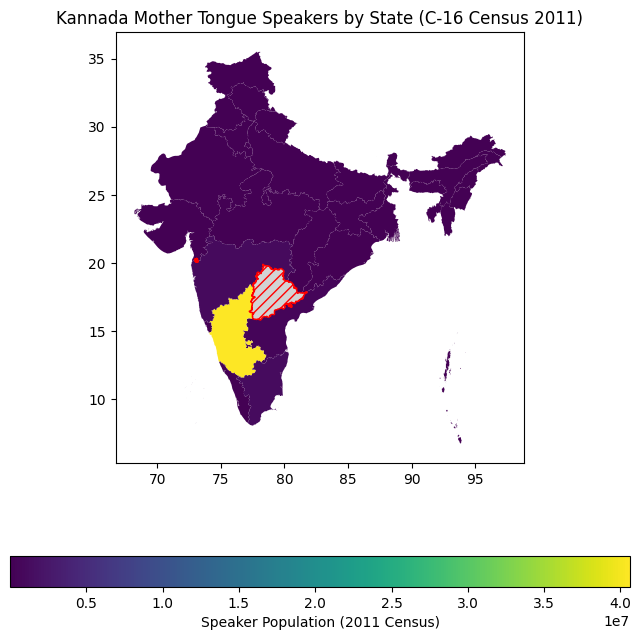

In [44]:
fig, ax = plt.subplots(figsize=(8,8))

kannada_map.plot(
    ax=ax,
    column="Total_P",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "red",
        "hatch": "///",
        "label": "Missing values",
    },
    legend_kwds={"label": "Speaker Population (2011 Census)", "orientation": "horizontal"}
);

ax.set_title(
    "Kannada Mother Tongue Speakers by State (C-16 Census 2011)", 
    fontsize=12
);

In [45]:
## Not including Karntaka

kannada_map_outside = kannada_map[kannada_map["NAME_1"] != "Karnataka"]
kannada_map_outside[["NAME_1", "Mother Tongue", "Total_P"]].dropna()

,NAME_1,Mother Tongue,Total_P
0,Andaman and Nicobar,Kannada,235.0
1,Andhra Pradesh,Kannada,532937.0
2,Arunachal Pradesh,Kannada,520.0
3,Arunachal Pradesh,Kannada,520.0
4,Assam,Kannada,2356.0
5,Bihar,Kannada,226.0
6,Chandigarh,Kannada,418.0
7,Chhattisgarh,Kannada,418.0
9,Daman and Diu,Kannada,432.0
10,Goa,Kannada,67837.0


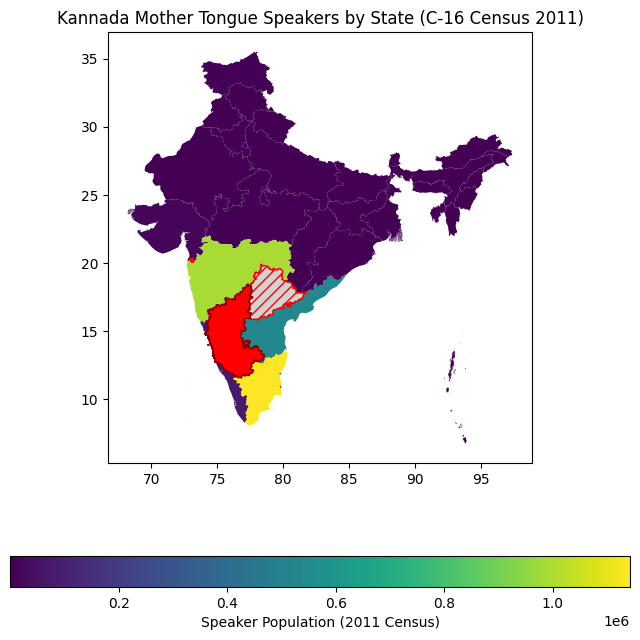

In [46]:
fig, ax = plt.subplots(figsize=(8,8))

kannada_map_outside.plot(
    ax=ax,
    column="Total_P",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "red",
        "hatch": "///",
        "label": "Missing values",
    },
    legend_kwds={"label": "Speaker Population (2011 Census)", "orientation": "horizontal"}
);


## Adding Karnataka to the map as a red element separate from Total_P
karnataka_geom = mal_map[mal_map["NAME_1"] == "Karnataka"]
karnataka_geom.plot(
    ax=ax, 
    color="red", 
    edgecolor="darkred",
    linewidth=1, 
    label="Karnataka (native state, excluded from scale)"
)

ax.set_title(
    "Kannada Mother Tongue Speakers by State (C-16 Census 2011)", 
    fontsize=12
);

In [47]:
### Making a Multiples Map Layout of Language Distributions that include the state of origin of language

In [48]:
all_maps = [mal_map, tamil_map, kannada_map, telugu_map]

In [49]:
titles = ["Malayalam", "Tamil", "Kannada", "Telugu"]

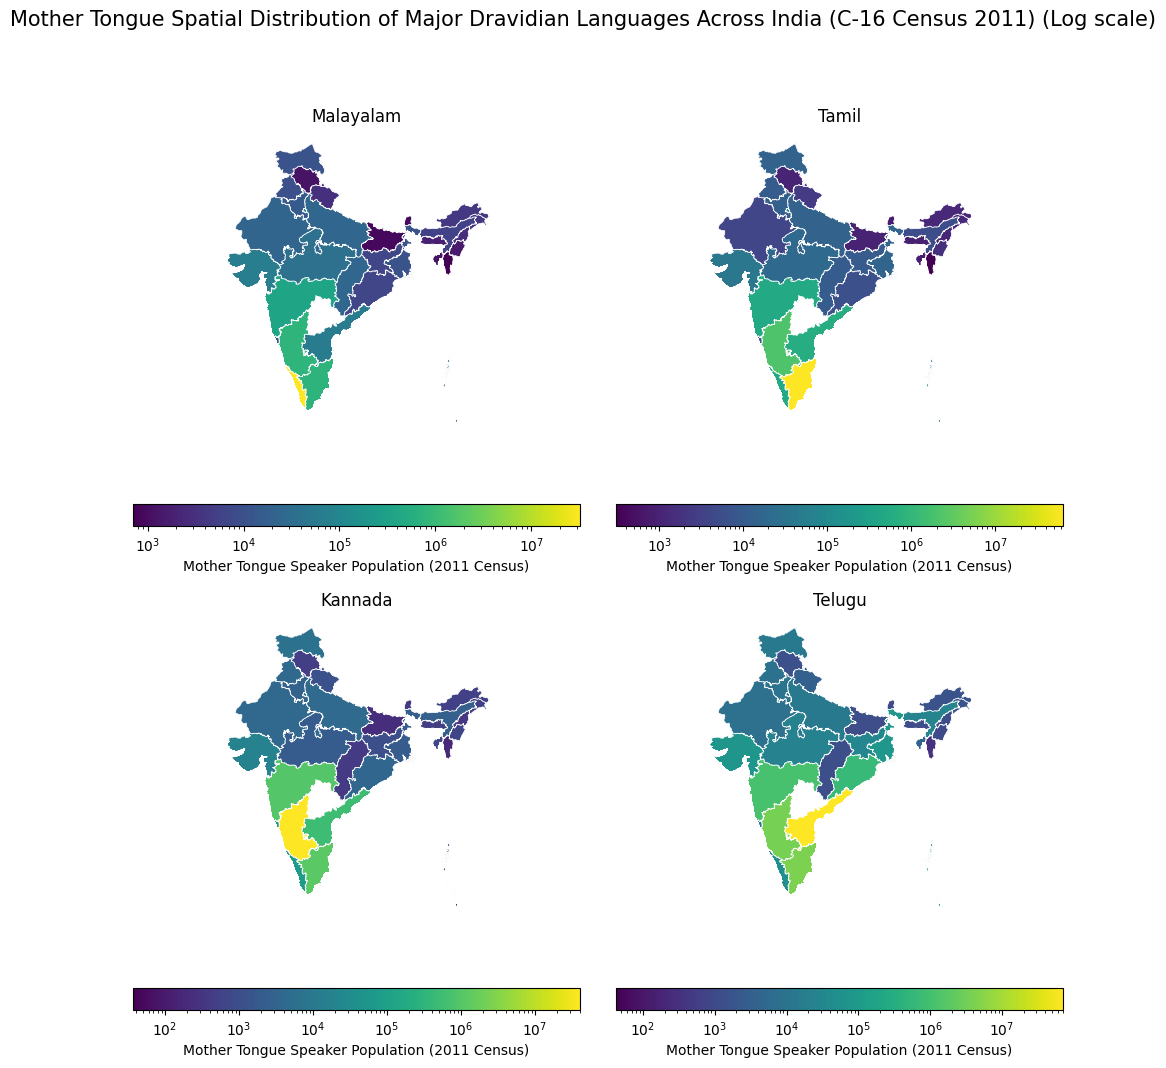

In [50]:
fig, ax = plt.subplots(2, 2, figsize=(12,12))

for map_data, title, subplot in zip(all_maps, titles, ax.flatten()):
    
    map_data.plot(
        ax=subplot,
        column="Total_P",
        norm=LogNorm(),
        legend=True, 
        edgecolor="white",
        linewidth=0.5,
        legend_kwds={"label": "Mother Tongue Speaker Population (2011 Census)", "orientation": "horizontal"}
    
    );
    
    subplot.set_title(title);
    subplot.axis('off')

#print(type(graph))

fig.subplots_adjust(wspace=0.08, hspace=0.1)
fig.suptitle("Mother Tongue Spatial Distribution of Major Dravidian Languages Across India (C-16 Census 2011) (Log scale)", fontsize=15);

## adding a visual gradient

#cmap = cm.viridis
#cax = ax.

# add a ScalarMappable object 
#sm = cm.ScalarMappable(cmap=cmap)
#cbar = fig.colorbar(sm, orientation="horizontal", ax=ax, pad=0.05, ticks=None);
#cbar.set_ticks([0, 1], labels=['Low Concentration', 'High Concentration'])

#colorizer = mpl.colors.(cmap='viridis')

In [51]:
### Making a Multiples Map Layout of Language Distributions that do NOT include the state of origin of language

In [52]:
all_outside_maps = [mal_map_outside, tam_map_outside, telugu_map_outside, kannada_map_outside]

In [53]:
titles = ["Malayalam", "Tamil", "Telugu", "Kannada"]

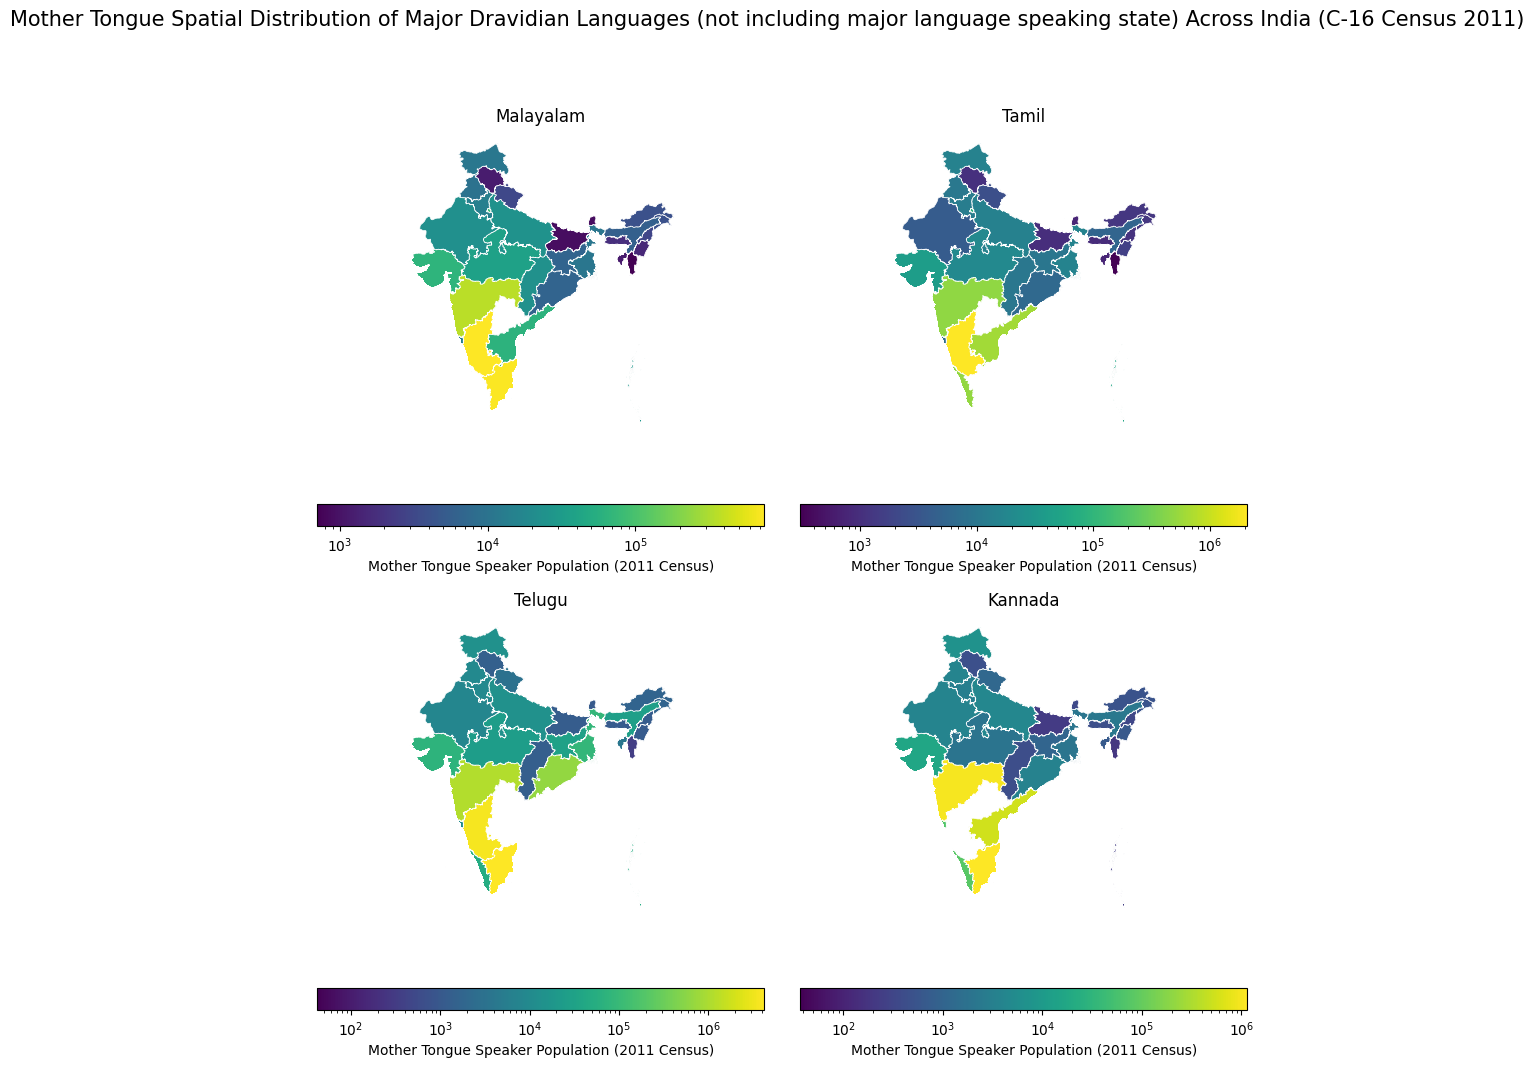

In [54]:
fig, ax = plt.subplots(2, 2, figsize=(12,12))

for map_data, title, subplot in zip(all_outside_maps, titles, ax.flatten()):
    
    map_data.plot(
        ax=subplot,
        column="Total_P",
        legend=True, 
        norm=LogNorm(),
        edgecolor="white",
        linewidth=0.5,
        legend_kwds={"label": "Mother Tongue Speaker Population (2011 Census)", "orientation": "horizontal"}
    
    );
    
    subplot.set_title(title);
    subplot.axis('off')

#print(type(graph))

fig.subplots_adjust(wspace=0.08, hspace=0.1)
fig.suptitle("Mother Tongue Spatial Distribution of Major Dravidian Languages (not including major language speaking state) Across India (C-16 Census 2011)", fontsize=15);

## adding a visual gradient

#cmap = cm.viridis
#cax = ax.

# add a ScalarMappable object 
#sm = cm.ScalarMappable(cmap=cmap)
#cbar = fig.colorbar(sm, orientation="horizontal", ax=ax, pad=0.05, ticks=None);
#cbar.set_ticks([0, 1], labels=['Low Concentration', 'High Concentration'])

#colorizer = mpl.colors.(cmap='viridis')

In [55]:
minor_tongues_df = pd.read_csv("dravidian-mother-tongues-minor-n-level.csv")
minor_tongues_df = minor_tongues_df.dropna()
minor_tongues_df

,Mother tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F
0,Tulu,1841963,899059,942904,1081821,525977,555844,760142,373082,387060
1,Gondi,2856581,1412226,1444355,2751694,1359001,1392693,104887,53225,51662
2,Kurukh/Oraon,1976920,986869,990051,1800364,899679,900685,176556,87190,89366
3,Kodagu/Coorgi,16939,8290,8649,2730,1378,1352,14209,6912,7297
4,Kui,941377,451357,490020,920177,441591,478586,21200,9766,11434
5,Kuvi,43855,20796,23059,43674,20704,22970,181,92,89
6,Kolami,128451,64423,64028,126112,63187,62925,2339,1236,1103
7,Konda,24987,12380,12607,24836,12276,12560,151,104,47
8,Irula/Irular Mozhi,11870,5850,6020,11297,5564,5733,573,286,287


In [56]:
### Making Bar Charts for each column 

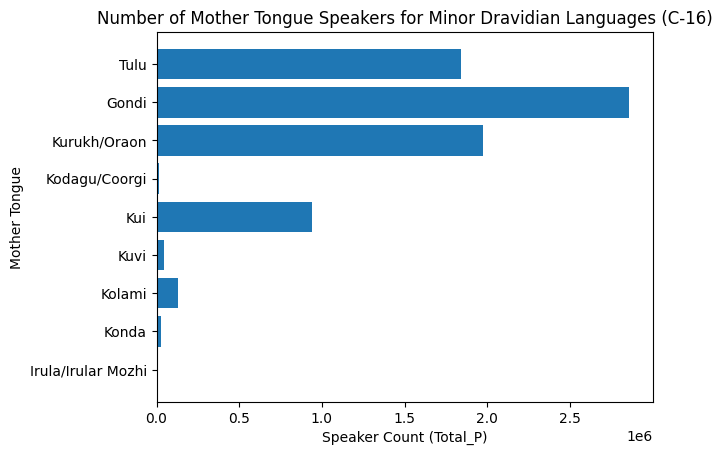

In [57]:
## Total_P

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df["Mother tongue"],
    minor_tongues_df["Total_P"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Total_P)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

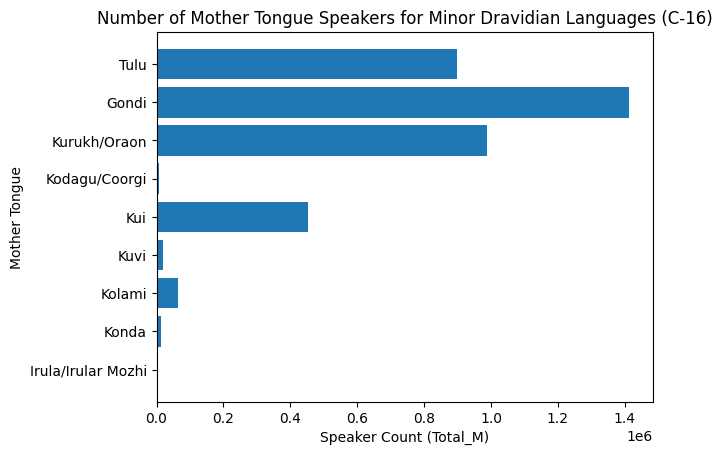

In [58]:
## Total_M

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df["Mother tongue"],
    minor_tongues_df["Total_M"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Total_M)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

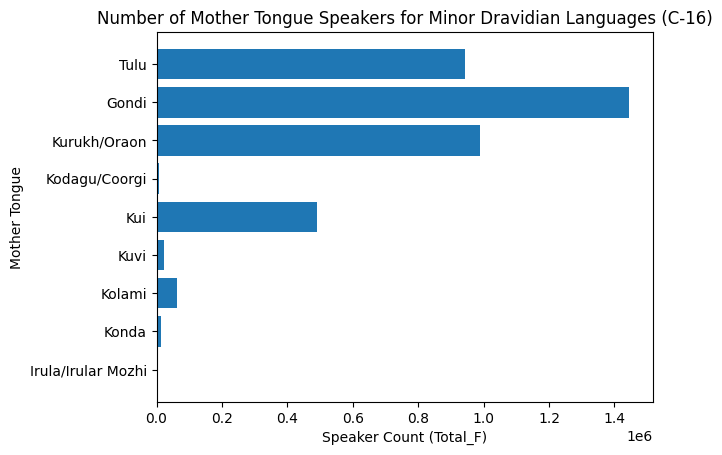

In [59]:
## Total_F

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df["Mother tongue"],
    minor_tongues_df["Total_F"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Total_F)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

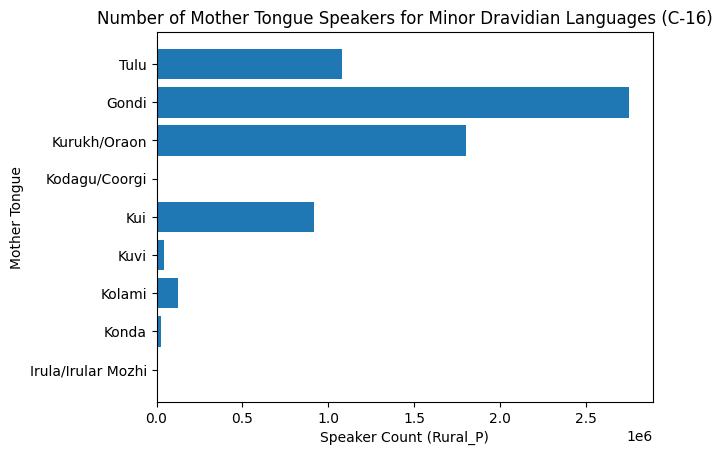

In [60]:
### Rural_P

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df["Mother tongue"],
    minor_tongues_df["Rural_P"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Rural_P)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

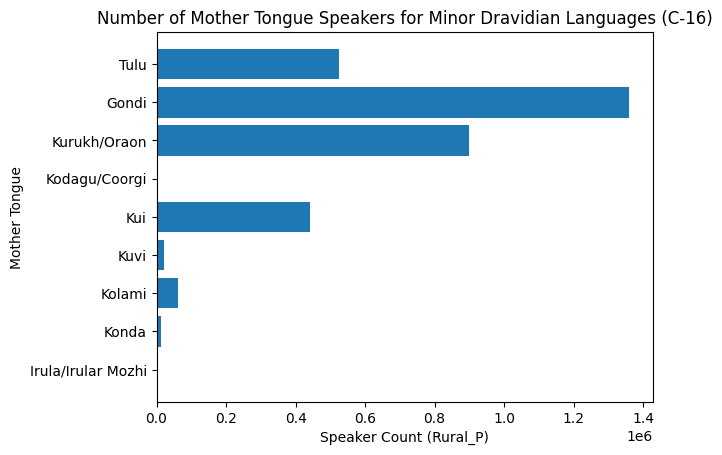

In [61]:
### Rural_M

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df["Mother tongue"],
    minor_tongues_df["Rural_M"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Rural_P)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

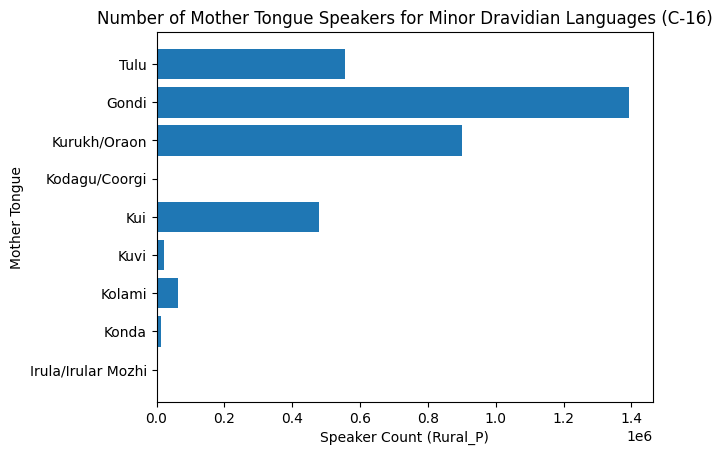

In [62]:
### Rural_F

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df["Mother tongue"],
    minor_tongues_df["Rural_F"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Rural_P)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

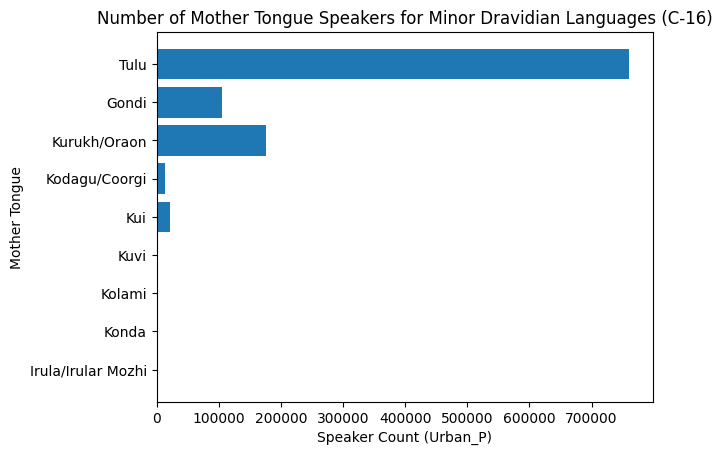

In [63]:
### Urban Population 

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df["Mother tongue"],
    minor_tongues_df["Urban_P"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Urban_P)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

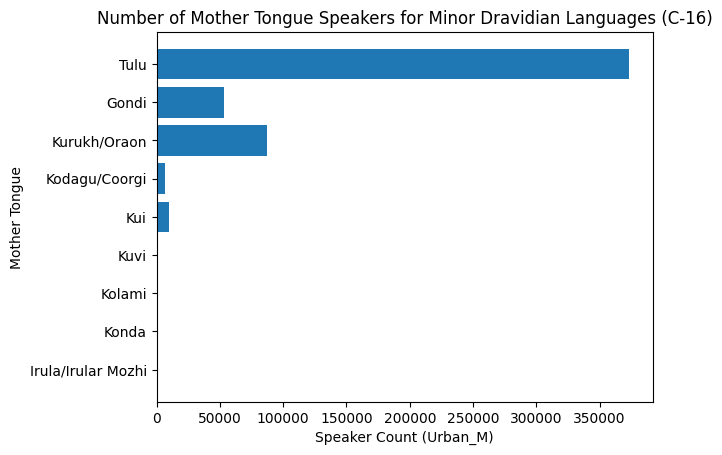

In [64]:
## Urban_M 

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df["Mother tongue"],
    minor_tongues_df["Urban_M"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Urban_M)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

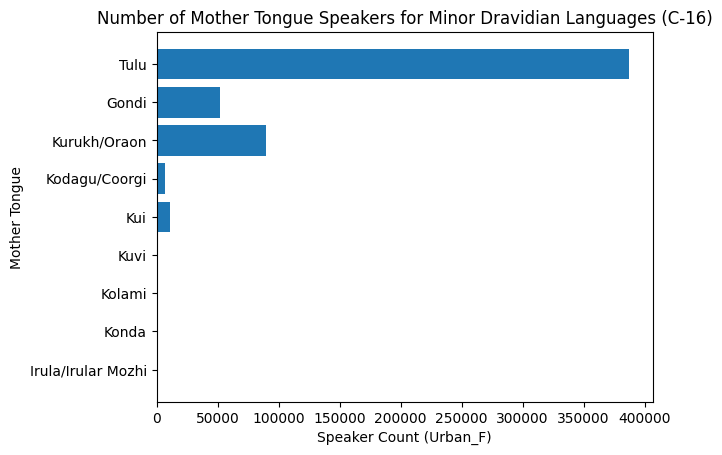

In [65]:
## Urban_F

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df["Mother tongue"],
    minor_tongues_df["Urban_F"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Urban_F)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

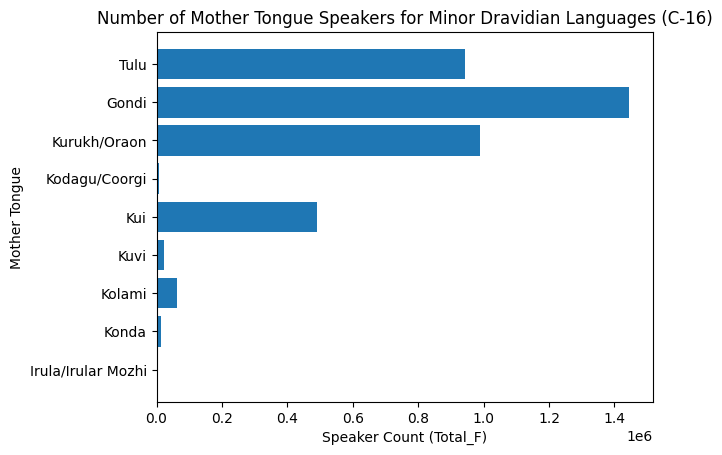

In [66]:
fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df["Mother tongue"],
    minor_tongues_df["Total_F"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Total_F)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

# Splitting the longer bars from the shorter bars 

## Longer Bars

In [67]:
## longer bars 
minor_tongues_df_top = minor_tongues_df.iloc[:5]
minor_tongues_df_top

,Mother tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F
0,Tulu,1841963,899059,942904,1081821,525977,555844,760142,373082,387060
1,Gondi,2856581,1412226,1444355,2751694,1359001,1392693,104887,53225,51662
2,Kurukh/Oraon,1976920,986869,990051,1800364,899679,900685,176556,87190,89366
3,Kodagu/Coorgi,16939,8290,8649,2730,1378,1352,14209,6912,7297
4,Kui,941377,451357,490020,920177,441591,478586,21200,9766,11434


### Total_P

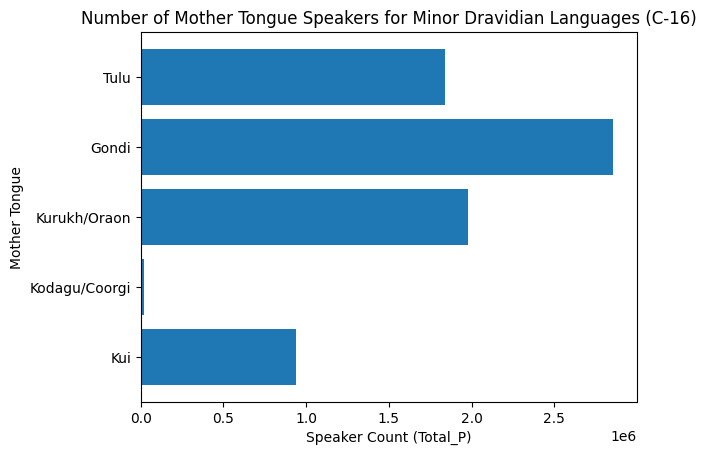

In [68]:
## Total_P

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_top["Mother tongue"],
    minor_tongues_df_top["Total_P"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Total_P)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

### Total_M

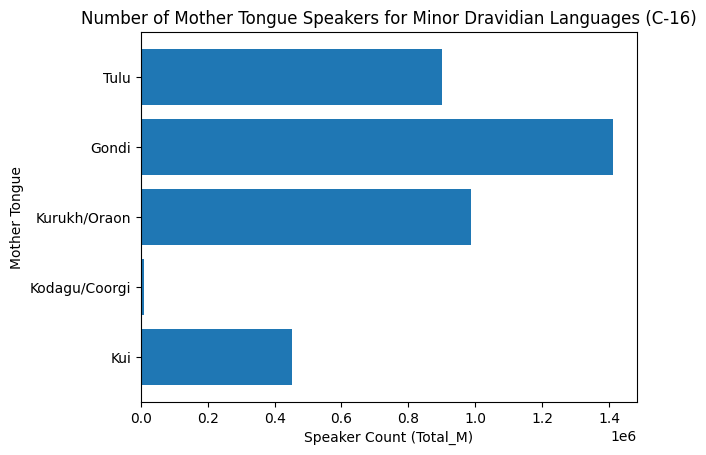

In [69]:
## Total_M

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_top["Mother tongue"],
    minor_tongues_df_top["Total_M"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Total_M)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

### Total_F

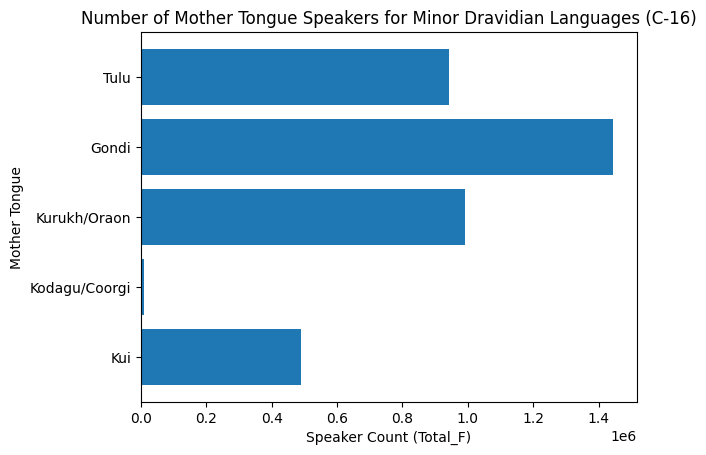

In [70]:
## Total_F

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_top["Mother tongue"],
    minor_tongues_df_top["Total_F"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Total_F)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

### Rural_P

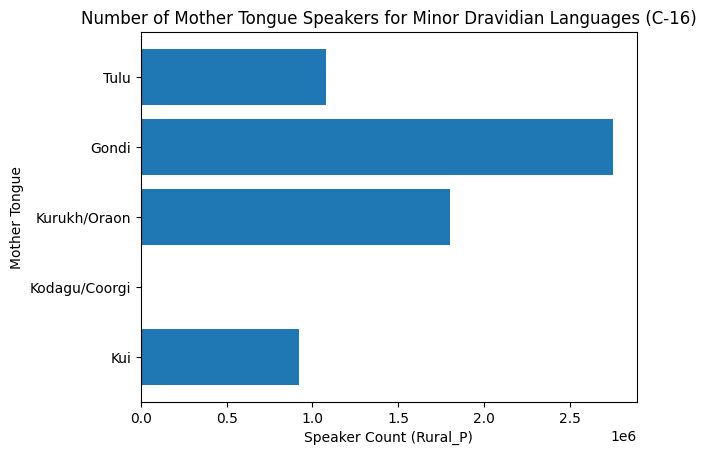

In [71]:
## Rural_P

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_top["Mother tongue"],
    minor_tongues_df_top["Rural_P"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Rural_P)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

### Rural_M

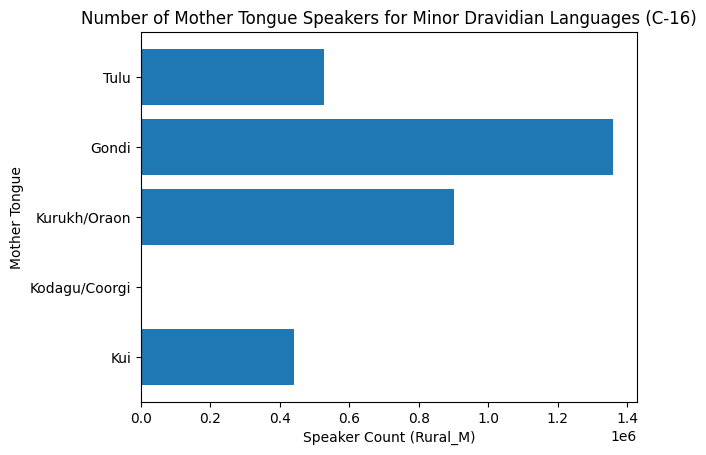

In [72]:
## Rural_M

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_top["Mother tongue"],
    minor_tongues_df_top["Rural_M"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Rural_M)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

### Rural_F

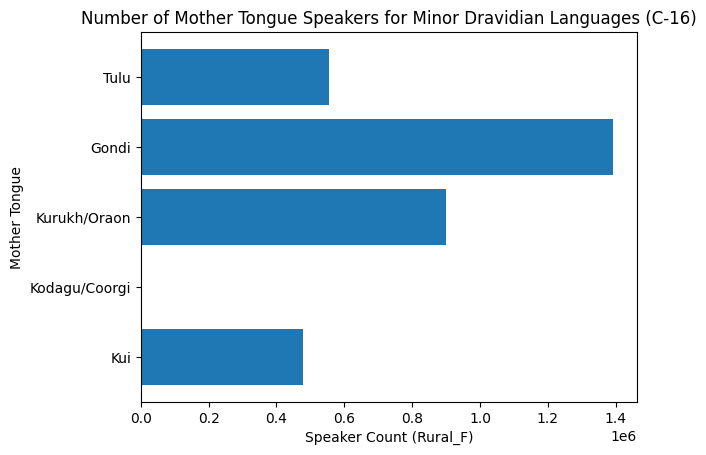

In [73]:
## Rural_F

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_top["Mother tongue"],
    minor_tongues_df_top["Rural_F"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Rural_F)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

### Urban_P

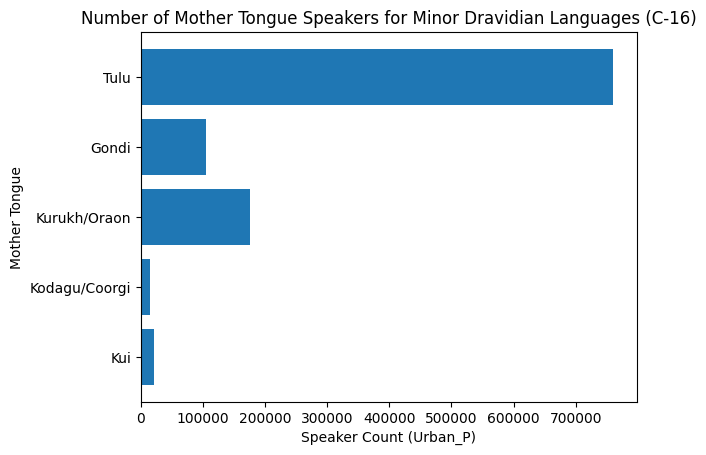

In [74]:
## Urban_P

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_top["Mother tongue"],
    minor_tongues_df_top["Urban_P"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Urban_P)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

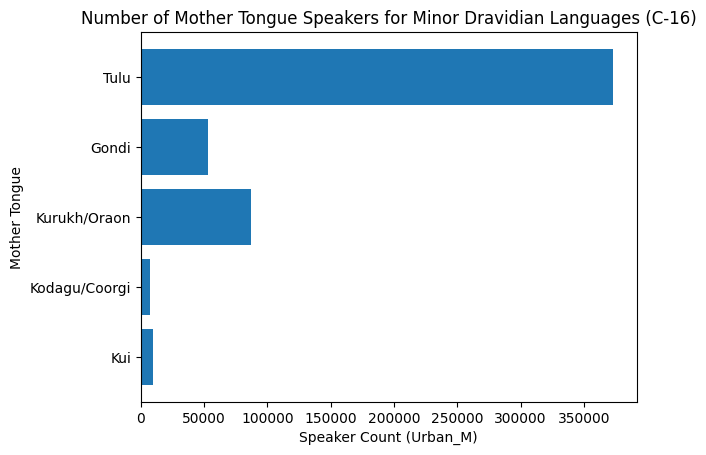

In [75]:
### Urban_M 

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_top["Mother tongue"],
    minor_tongues_df_top["Urban_M"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Urban_M)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

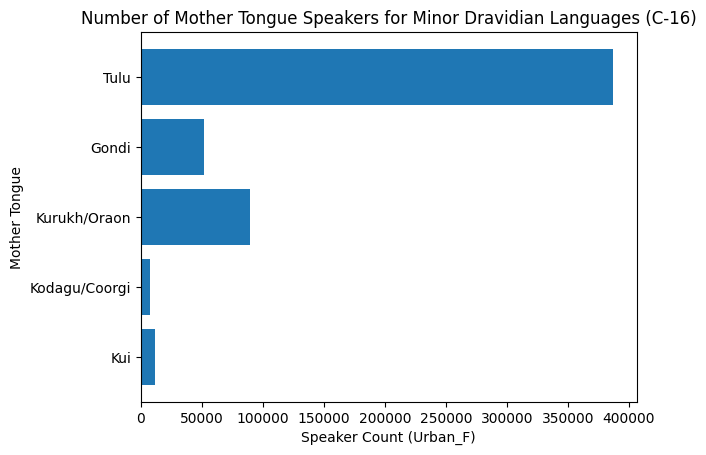

In [76]:
### Urban_F

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_top["Mother tongue"],
    minor_tongues_df_top["Urban_F"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Urban_F)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

## Shorter Bars

In [77]:
### shorter bars 
minor_tongues_df_bottom = minor_tongues_df.iloc[-4:]
minor_tongues_df_bottom

,Mother tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F
5,Kuvi,43855,20796,23059,43674,20704,22970,181,92,89
6,Kolami,128451,64423,64028,126112,63187,62925,2339,1236,1103
7,Konda,24987,12380,12607,24836,12276,12560,151,104,47
8,Irula/Irular Mozhi,11870,5850,6020,11297,5564,5733,573,286,287


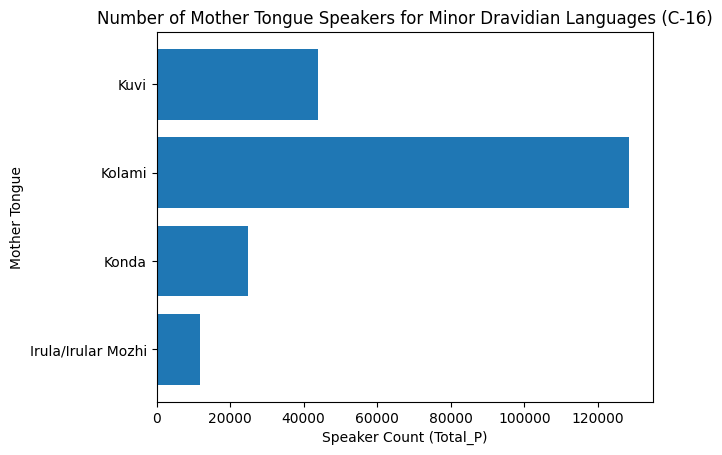

In [78]:
### Total_P

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_bottom["Mother tongue"],
    minor_tongues_df_bottom["Total_P"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Total_P)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

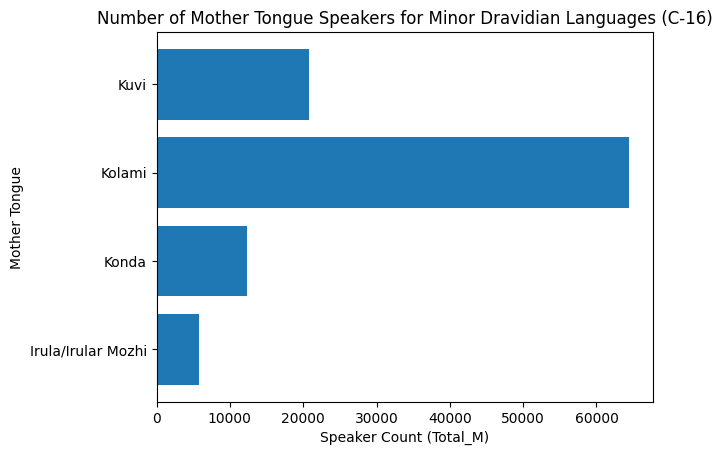

In [79]:
### Total_M

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_bottom["Mother tongue"],
    minor_tongues_df_bottom["Total_M"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Total_M)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

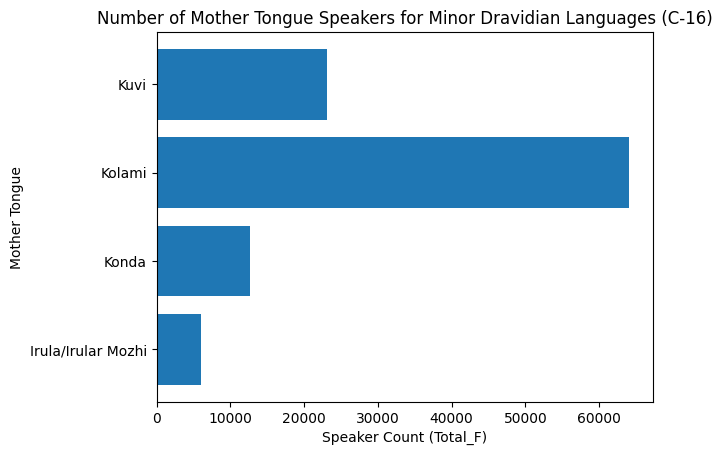

In [80]:
### Total_F

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_bottom["Mother tongue"],
    minor_tongues_df_bottom["Total_F"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Total_F)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

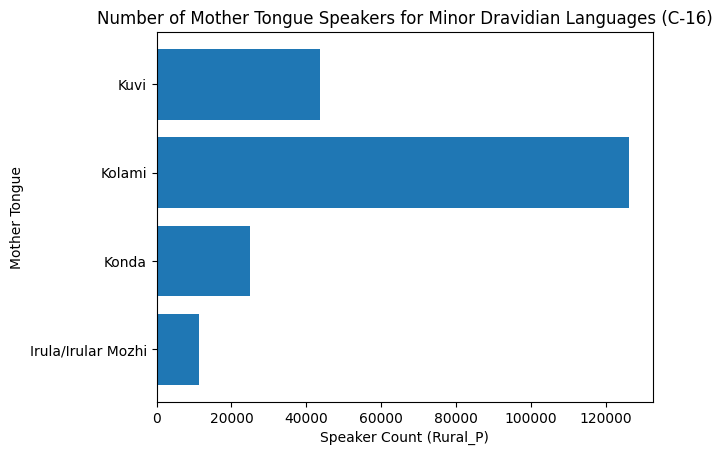

In [81]:
### Rural_P

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_bottom["Mother tongue"],
    minor_tongues_df_bottom["Rural_P"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Rural_P)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

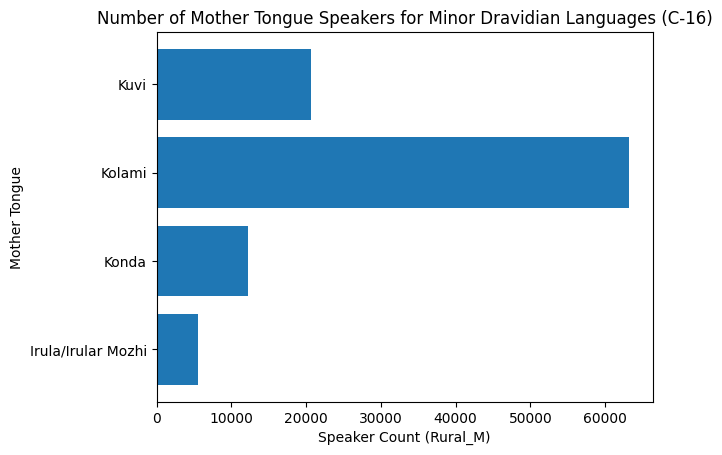

In [82]:
### Rural_M

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_bottom["Mother tongue"],
    minor_tongues_df_bottom["Rural_M"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Rural_M)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

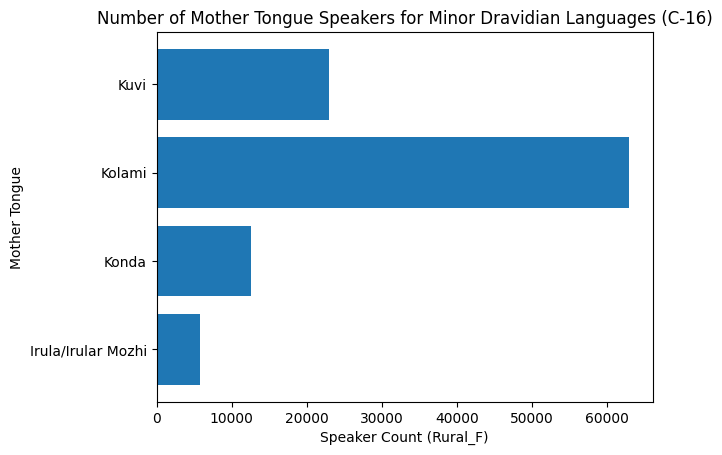

In [83]:
### Rural_F

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_bottom["Mother tongue"],
    minor_tongues_df_bottom["Rural_F"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Rural_F)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

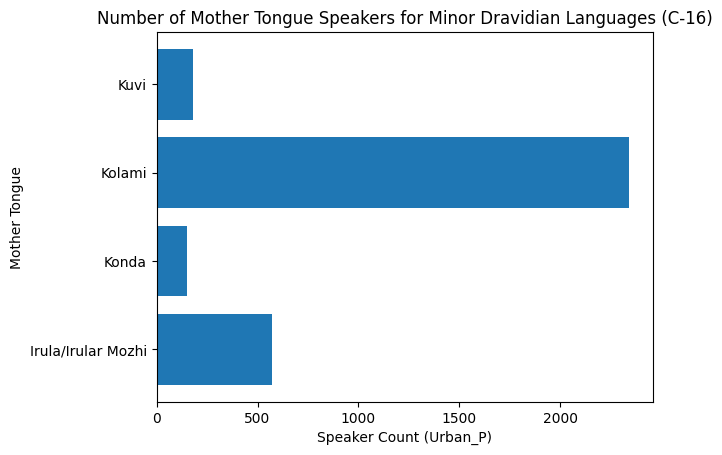

In [84]:
### Urban_P

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_bottom["Mother tongue"],
    minor_tongues_df_bottom["Urban_P"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Urban_P)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

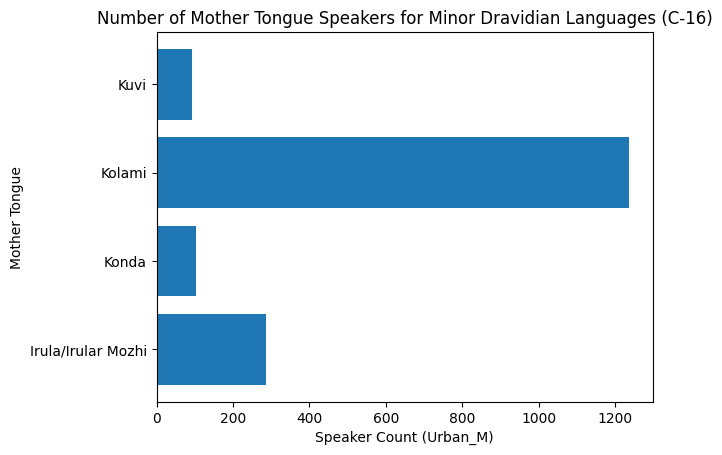

In [85]:
### Urban_M

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_bottom["Mother tongue"],
    minor_tongues_df_bottom["Urban_M"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Urban_M)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

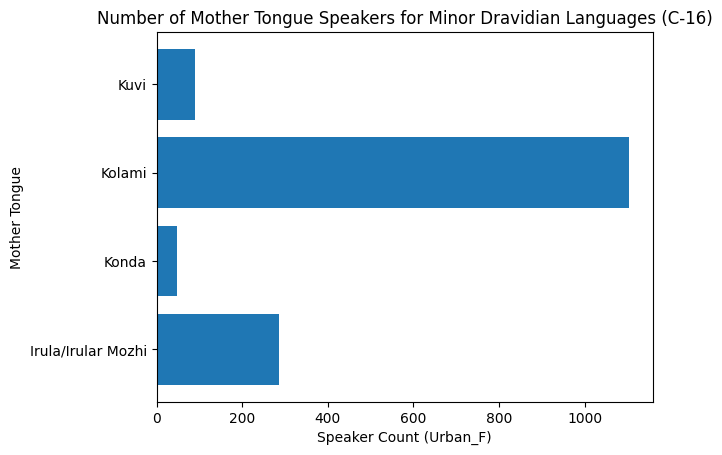

In [86]:
### Urban_F

fig, ax = plt.subplots()

# Example data
ax.barh(
    minor_tongues_df_bottom["Mother tongue"],
    minor_tongues_df_bottom["Urban_F"]
)
ax.set_ylabel("Mother Tongue")
ax.set_xlabel("Speaker Count (Urban_F)")
ax.set_title("Number of Mother Tongue Speakers for Minor Dravidian Languages (C-16)")
ax.invert_yaxis()

plt.show()

# Making a Multiples Map of Longer vs Shorter Bars 

## Multiples Map (Longer Bars) 

In [87]:
columns = ["Total_P", "Total_M", "Total_F", "Rural_P", "Rural_M", "Rural_F", "Urban_P", "Urban_M", "Urban_F"]

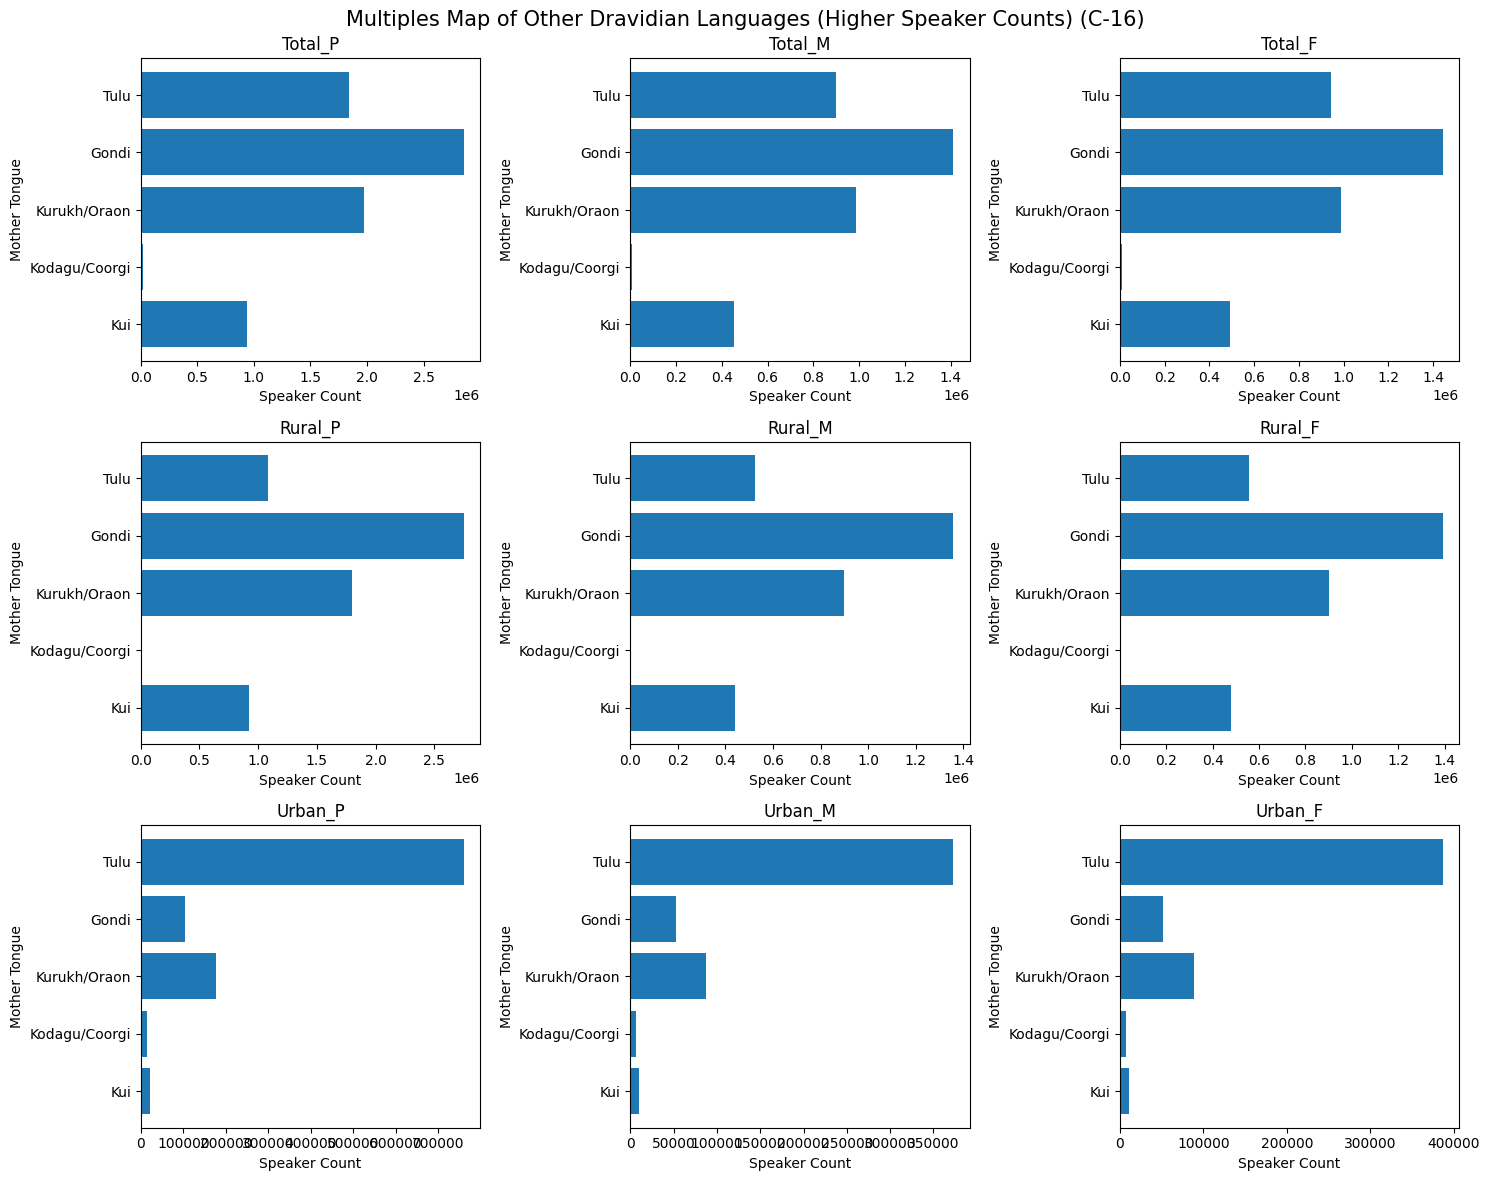

In [88]:
### Longer

fig, ax= plt.subplots(3,3, figsize=(15,12))

for position, total_x in enumerate(columns): 
    row = position//3
    col = position%3
            
    # Example data
    ax[row, col].barh(
        minor_tongues_df_top["Mother tongue"],
        minor_tongues_df_top[total_x]
    )
    ax[row, col].set_ylabel("Mother Tongue")
    ax[row, col].set_xlabel("Speaker Count")
    ax[row, col].set_title(total_x)
    ax[row, col].invert_yaxis()

fig.suptitle("Multiples Map of Other Dravidian Languages (Higher Speaker Counts) (C-16)", fontsize=15);

plt.tight_layout()
plt.show()

## Multiples Map (Shorter Bars) 

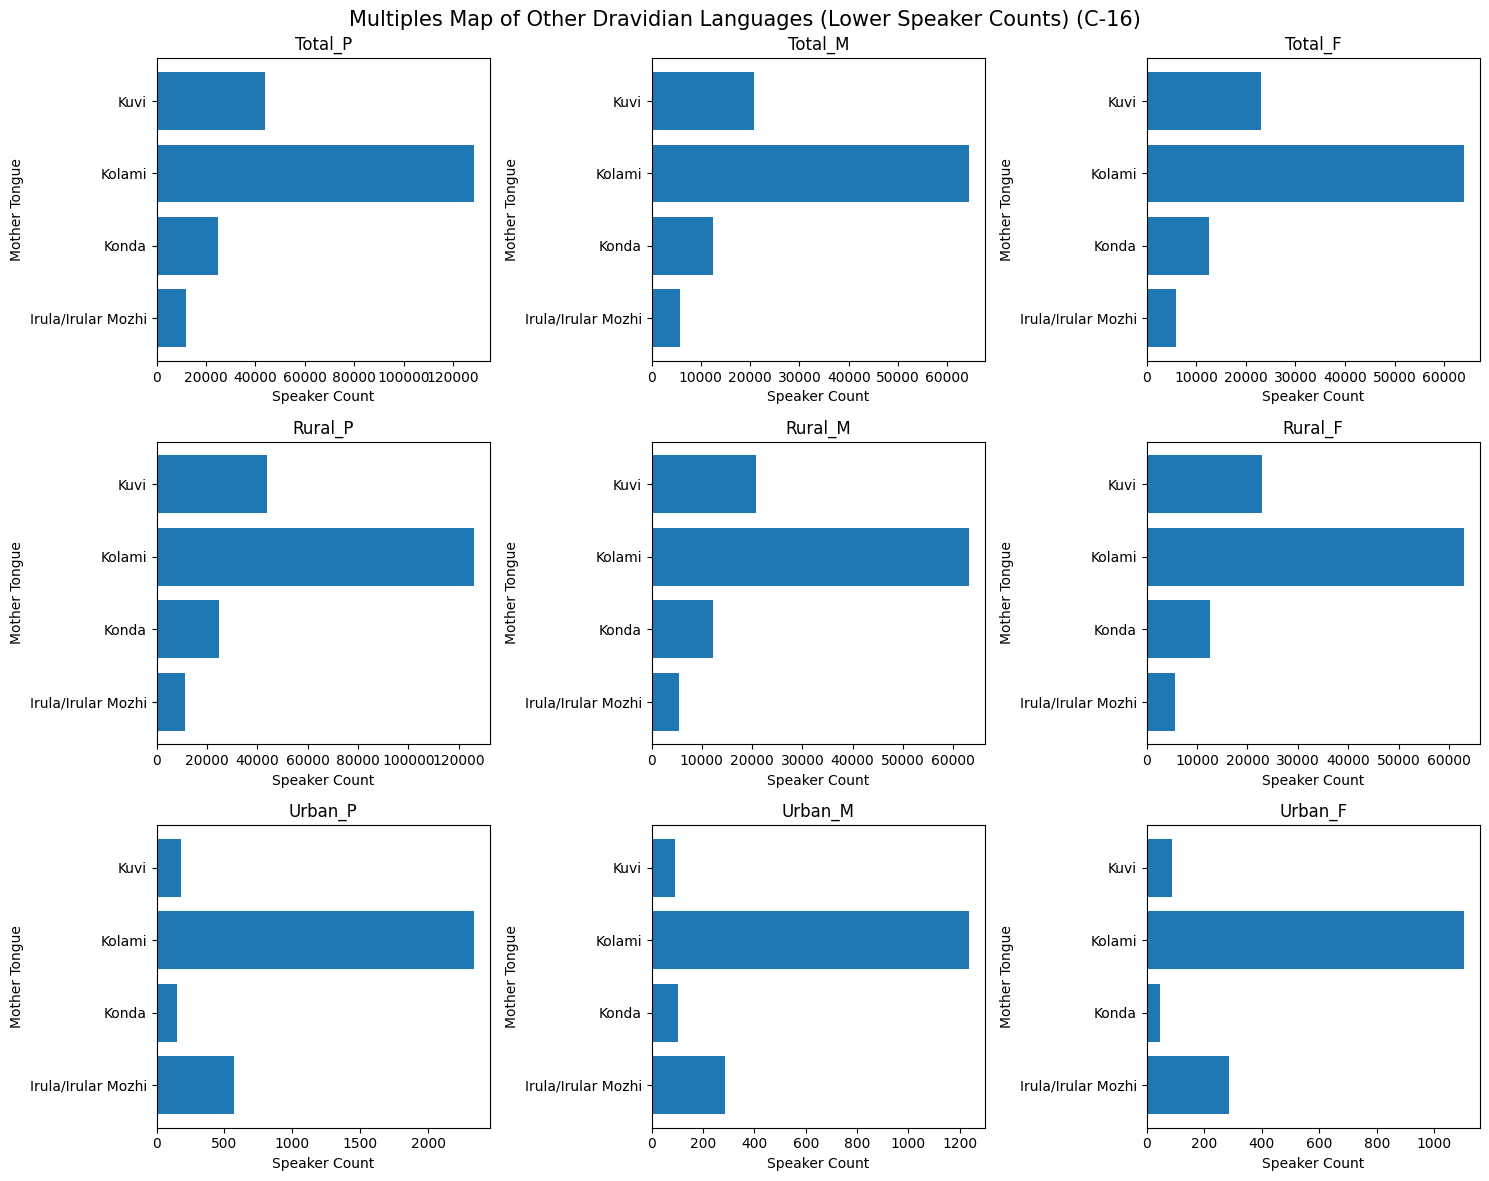

In [89]:
### Longer

fig, ax= plt.subplots(3,3, figsize=(15,12))

for position, total_x in enumerate(columns): 
    row = position//3
    col = position%3
            
    # Example data
    ax[row, col].barh(
        minor_tongues_df_bottom["Mother tongue"],
        minor_tongues_df_bottom[total_x]
    )
    ax[row, col].set_ylabel("Mother Tongue")
    ax[row, col].set_xlabel("Speaker Count")
    ax[row, col].set_title(total_x)
    ax[row, col].invert_yaxis()


fig.suptitle("Multiples Map of Other Dravidian Languages (Lower Speaker Counts) (C-16)", fontsize=15);
plt.tight_layout()

plt.show()

In [90]:
### Need to make this a 100% Stacked Bar Chart - working with minor_tongues_df

In [91]:
rural_urban_df = minor_tongues_df[["Mother tongue", "Rural_P", "Urban_P", "Total_P"]].copy()
rural_urban_df

,Mother tongue,Rural_P,Urban_P,Total_P
0,Tulu,1081821,760142,1841963
1,Gondi,2751694,104887,2856581
2,Kurukh/Oraon,1800364,176556,1976920
3,Kodagu/Coorgi,2730,14209,16939
4,Kui,920177,21200,941377
5,Kuvi,43674,181,43855
6,Kolami,126112,2339,128451
7,Konda,24836,151,24987
8,Irula/Irular Mozhi,11297,573,11870


In [92]:
## adding a new column titled rural-share and urban-share
rural_urban_df["rural-share"] = rural_urban_df["Rural_P"]/rural_urban_df["Total_P"]
rural_urban_df["urban-share"] = rural_urban_df["Urban_P"]/rural_urban_df["Total_P"]
rural_urban_df

,Mother tongue,Rural_P,Urban_P,Total_P,rural-share,urban-share
0,Tulu,1081821,760142,1841963,0.587320,0.412680
1,Gondi,2751694,104887,2856581,0.963282,0.036718
2,Kurukh/Oraon,1800364,176556,1976920,0.910691,0.089309
3,Kodagu/Coorgi,2730,14209,16939,0.161167,0.838833
4,Kui,920177,21200,941377,0.977480,0.022520
5,Kuvi,43674,181,43855,0.995873,0.004127
6,Kolami,126112,2339,128451,0.981791,0.018209
7,Konda,24836,151,24987,0.993957,0.006043
8,Irula/Irular Mozhi,11297,573,11870,0.951727,0.048273


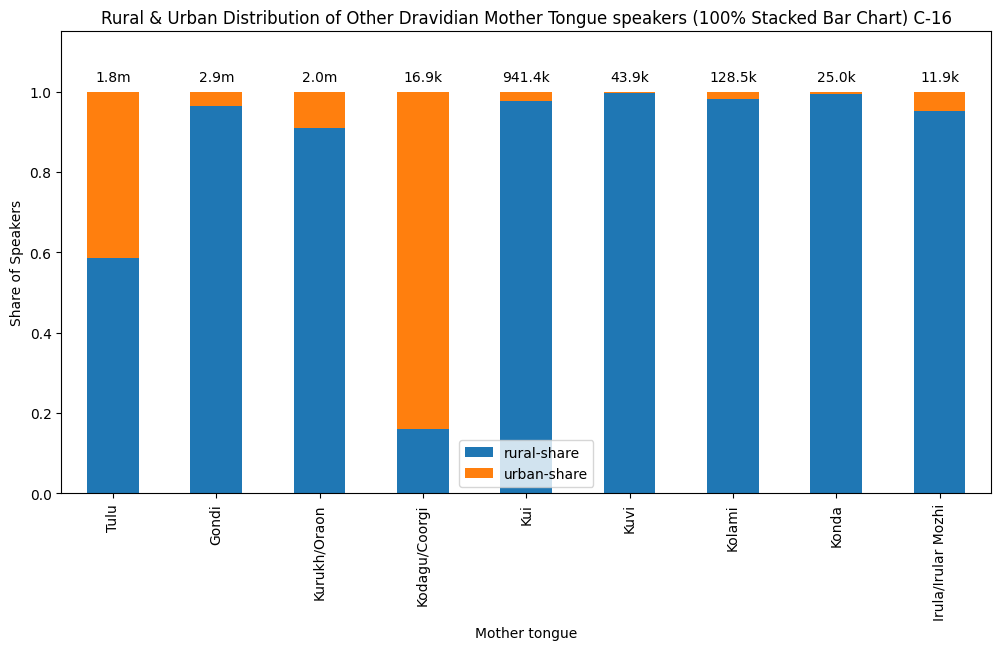

In [93]:
ax = rural_urban_df.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6), 
    x="Mother tongue",
    y=["rural-share", "urban-share"],
)
plt.xlabel("Mother tongue")
plt.ylabel("Share of Speakers");
plt.title("Rural & Urban Distribution of Other Dravidian Mother Tongue speakers (100% Stacked Bar Chart) C-16");

for position, population in enumerate(rural_urban_df["Total_P"]): 
    if population >= 1000000:
        population = population/1000000
        label = f"{population:.1f}m"
    elif population >= 1000: 
        population = population/1000
        label = f"{population:.1f}k"

    ax.text(position, 1.02, label, ha="center", va="bottom")
    ax.set_ylim(0, 1.15)

### kurukh/oraon and kodagu/coorgi have identical counts, i believe that was a typo needing correction

In [94]:
## Making another stacked bar chart for male vs female speakers

In [95]:
male_female_df = minor_tongues_df[["Mother tongue", "Total_M", "Total_F", "Total_P"]].copy()
male_female_df

,Mother tongue,Total_M,Total_F,Total_P
0,Tulu,899059,942904,1841963
1,Gondi,1412226,1444355,2856581
2,Kurukh/Oraon,986869,990051,1976920
3,Kodagu/Coorgi,8290,8649,16939
4,Kui,451357,490020,941377
5,Kuvi,20796,23059,43855
6,Kolami,64423,64028,128451
7,Konda,12380,12607,24987
8,Irula/Irular Mozhi,5850,6020,11870


In [96]:
## adding a new column titled male-share and female-share
male_female_df["male_share"] = male_female_df["Total_M"]/male_female_df["Total_P"]
male_female_df["female-share"] = male_female_df["Total_F"]/male_female_df["Total_P"]
male_female_df

,Mother tongue,Total_M,Total_F,Total_P,male_share,female-share
0,Tulu,899059,942904,1841963,0.488098,0.511902
1,Gondi,1412226,1444355,2856581,0.494376,0.505624
2,Kurukh/Oraon,986869,990051,1976920,0.499195,0.500805
3,Kodagu/Coorgi,8290,8649,16939,0.489403,0.510597
4,Kui,451357,490020,941377,0.479465,0.520535
5,Kuvi,20796,23059,43855,0.474199,0.525801
6,Kolami,64423,64028,128451,0.501538,0.498462
7,Konda,12380,12607,24987,0.495458,0.504542
8,Irula/Irular Mozhi,5850,6020,11870,0.492839,0.507161


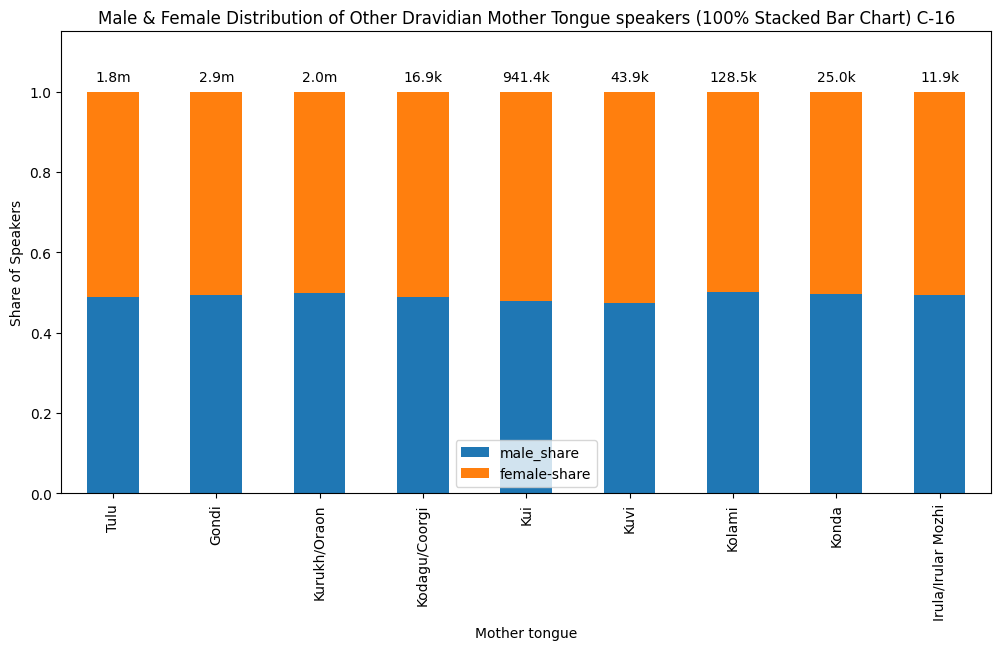

In [97]:
ax = male_female_df.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6), 
    x="Mother tongue",
    y=["male_share", "female-share"],
)
plt.xlabel("Mother tongue")
plt.ylabel("Share of Speakers");
plt.title("Male & Female Distribution of Other Dravidian Mother Tongue speakers (100% Stacked Bar Chart) C-16");


for position, population in enumerate(male_female_df["Total_P"]): 
    if population >= 1000000:
        population = population/1000000
        label = f"{population:.1f}m"
    elif population >= 1000: 
        population = population/1000
        label = f"{population:.1f}k"

    ax.text(position, 1.02, label, ha="center", va="bottom")
ax.set_ylim(0, 1.15);

In [98]:
## Making a stacked bar chart for the main 4 dravidian languages as well? 

In [99]:
main_df = pd.read_csv("dravidian-mother-tongues-main-n-level.csv")
main_df = main_df.dropna()
main_df

,Mother tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F
0,Malayalam,34776533,16681977,18094556,17355542,8339365,9016177,17420991,8342612,9078379
1,Tamil,68888839,34531580,34357259,35530671,17829882,17700789,33358168,16701698,16656470
2,Telugu,80912459,40549767,40362692,53738513,26918237,26820276,27173946,13631530,13542416
3,Kannada,43506272,22014001,21492271,30614889,15462374,15152515,12891383,6551627,6339756
4,Tulu,1841963,899059,942904,1081821,525977,555844,760142,373082,387060


In [100]:
## adding a new column titled rural-share and urban-share
main_rural_urban_df = main_df[["Mother tongue", "Rural_P", "Urban_P", "Total_P"]].copy()
main_rural_urban_df

,Mother tongue,Rural_P,Urban_P,Total_P
0,Malayalam,17355542,17420991,34776533
1,Tamil,35530671,33358168,68888839
2,Telugu,53738513,27173946,80912459
3,Kannada,30614889,12891383,43506272
4,Tulu,1081821,760142,1841963


In [101]:
## adding a new column titled rural-share and urban-share
main_rural_urban_df["rural-share"] = main_rural_urban_df["Rural_P"]/main_rural_urban_df["Total_P"]
main_rural_urban_df["urban-share"] = main_rural_urban_df["Urban_P"]/main_rural_urban_df["Total_P"]
main_rural_urban_df

,Mother tongue,Rural_P,Urban_P,Total_P,rural-share,urban-share
0,Malayalam,17355542,17420991,34776533,0.499059,0.500941
1,Tamil,35530671,33358168,68888839,0.515768,0.484232
2,Telugu,53738513,27173946,80912459,0.664156,0.335844
3,Kannada,30614889,12891383,43506272,0.703689,0.296311
4,Tulu,1081821,760142,1841963,0.587320,0.412680


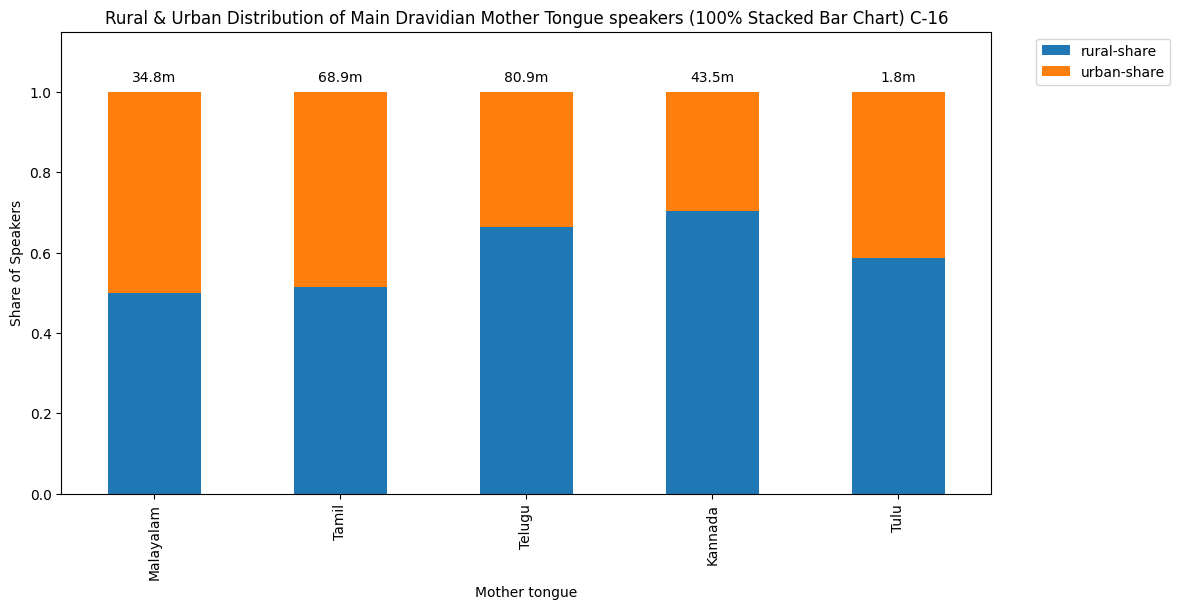

In [102]:
ax = main_rural_urban_df.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6), 
    x="Mother tongue",
    y=["rural-share", "urban-share"],
)
plt.xlabel("Mother tongue")
plt.ylabel("Share of Speakers");
plt.title("Rural & Urban Distribution of Main Dravidian Mother Tongue speakers (100% Stacked Bar Chart) C-16");

for position, population in enumerate(main_rural_urban_df["Total_P"]): 
    if population >= 1000000:
        population = population/1000000
        label = f"{population:.1f}m"
    elif population >= 1000: 
        population = population/1000
        label = f"{population:.1f}k"

    ax.text(position, 1.02, label, ha="center", va="bottom")
    ax.legend(bbox_to_anchor=(1.2, 1))
    ax.set_ylim(0, 1.15);
    

In [103]:
## doing the same thing for male-female 
main_male_female_df = main_df[["Mother tongue", "Total_M", "Total_F", "Total_P"]].copy()
main_male_female_df

,Mother tongue,Total_M,Total_F,Total_P
0,Malayalam,16681977,18094556,34776533
1,Tamil,34531580,34357259,68888839
2,Telugu,40549767,40362692,80912459
3,Kannada,22014001,21492271,43506272
4,Tulu,899059,942904,1841963


In [104]:
## adding a new column titled male-share and female-share
main_male_female_df["male-share"] = main_male_female_df["Total_M"]/main_male_female_df["Total_P"]
main_male_female_df["female-share"] = main_male_female_df["Total_F"]/main_male_female_df["Total_P"]
main_male_female_df

,Mother tongue,Total_M,Total_F,Total_P,male-share,female-share
0,Malayalam,16681977,18094556,34776533,0.479691,0.520309
1,Tamil,34531580,34357259,68888839,0.501265,0.498735
2,Telugu,40549767,40362692,80912459,0.501156,0.498844
3,Kannada,22014001,21492271,43506272,0.505996,0.494004
4,Tulu,899059,942904,1841963,0.488098,0.511902


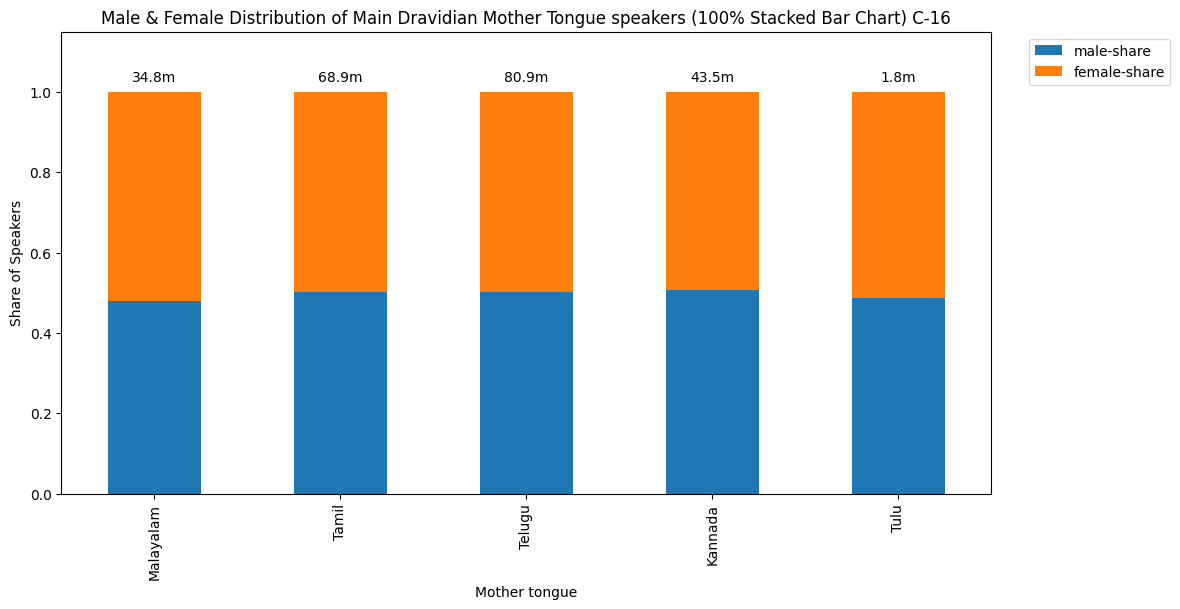

In [108]:
ax = main_male_female_df.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6), 
    x="Mother tongue",
    y=["male-share", "female-share"],
)
plt.xlabel("Mother tongue")
plt.ylabel("Share of Speakers");
plt.title("Male & Female Distribution of Main Dravidian Mother Tongue speakers (100% Stacked Bar Chart) C-16");

for position, population in enumerate(main_rural_urban_df["Total_P"]): 
    if population >= 1000000:
        population = population/1000000
        label = f"{population:.1f}m"
    elif population >= 1000: 
        population = population/1000
        label = f"{population:.1f}k"

    ax.text(position, 1.02, label, ha="center", va="bottom")
    ax.legend(bbox_to_anchor=(1.2, 1))
    ax.set_ylim(0, 1.15);

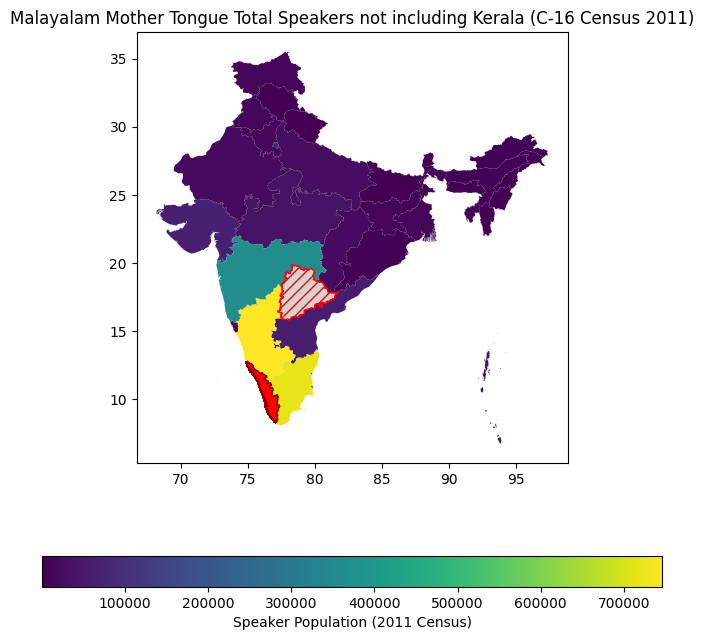

In [109]:
### Back to mapping minority Dravidian languages? 
## Starting with Kerala again 
fig, ax = plt.subplots(figsize=(8,8))

mal_map_outside.plot(
    ax=ax,
    column="Total_P",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "red",
        "hatch": "///",
        "label": "Missing values",
    },
    legend_kwds={"label": "Speaker Population (2011 Census)", "orientation": "horizontal"}
);


## Adding Kerala to the map as a red element separate from Total_P
kerala_geom = mal_map[mal_map["NAME_1"] == "Kerala"]
kerala_geom.plot(
    ax=ax, 
    color="red", 
    edgecolor="darkred",
    linewidth=1, 
    label="Kerala (native state, excluded from scale)"
)

ax.set_title(
    "Malayalam Mother Tongue Total Speakers not including Kerala (C-16 Census 2011)", 
    fontsize=12
);

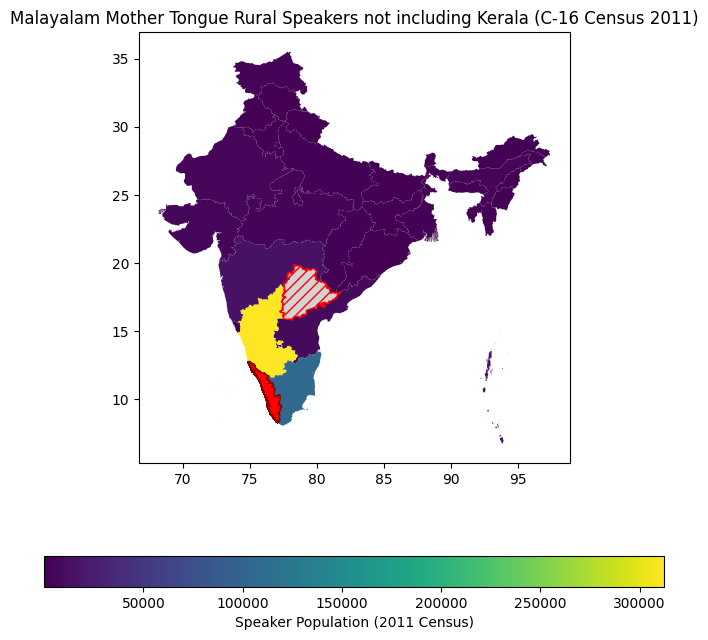

In [110]:
## Rural 
fig, ax = plt.subplots(figsize=(8,8))

mal_map_outside.plot(
    ax=ax,
    column="Rural_P",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "red",
        "hatch": "///",
        "label": "Missing values",
    },
    legend_kwds={"label": "Speaker Population (2011 Census)", "orientation": "horizontal"}
);


## Adding Kerala to the map as a red element separate from Total_P
kerala_geom = mal_map[mal_map["NAME_1"] == "Kerala"]
kerala_geom.plot(
    ax=ax, 
    color="red", 
    edgecolor="darkred",
    linewidth=1, 
    label="Kerala (native state, excluded from scale)"
)

ax.set_title(
    "Malayalam Mother Tongue Rural Speakers not including Kerala (C-16 Census 2011)", 
    fontsize=12
);

### Multiples Map Layout

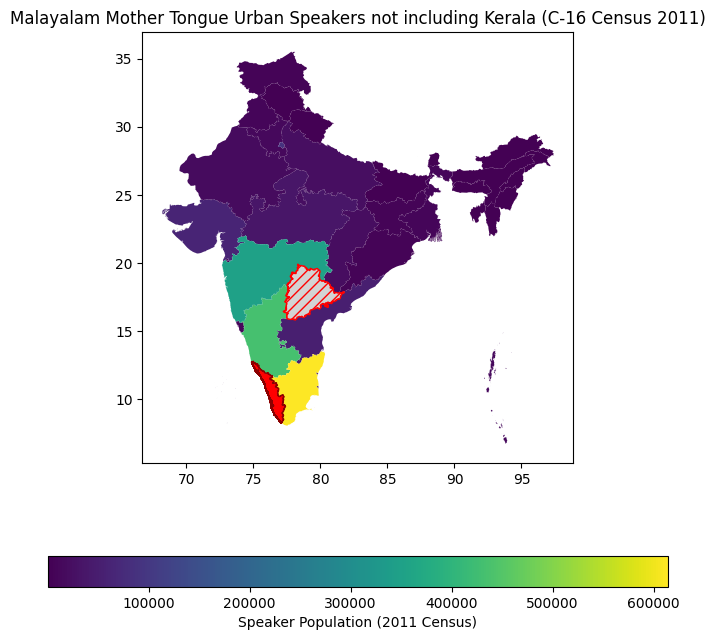

In [111]:
## Urban
fig, ax = plt.subplots(figsize=(8,8))

mal_map_outside.plot(
    ax=ax,
    column="Urban_P",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "red",
        "hatch": "///",
        "label": "Missing values",
    },
    legend_kwds={"label": "Speaker Population (2011 Census)", "orientation": "horizontal"}
);


## Adding Kerala to the map as a red element separate from Total_P
kerala_geom = mal_map[mal_map["NAME_1"] == "Kerala"]
kerala_geom.plot(
    ax=ax, 
    color="red", 
    edgecolor="darkred",
    linewidth=1, 
    label="Kerala (native state, excluded from scale)"
)

ax.set_title(
    "Malayalam Mother Tongue Urban Speakers not including Kerala (C-16 Census 2011)", 
    fontsize=12
);

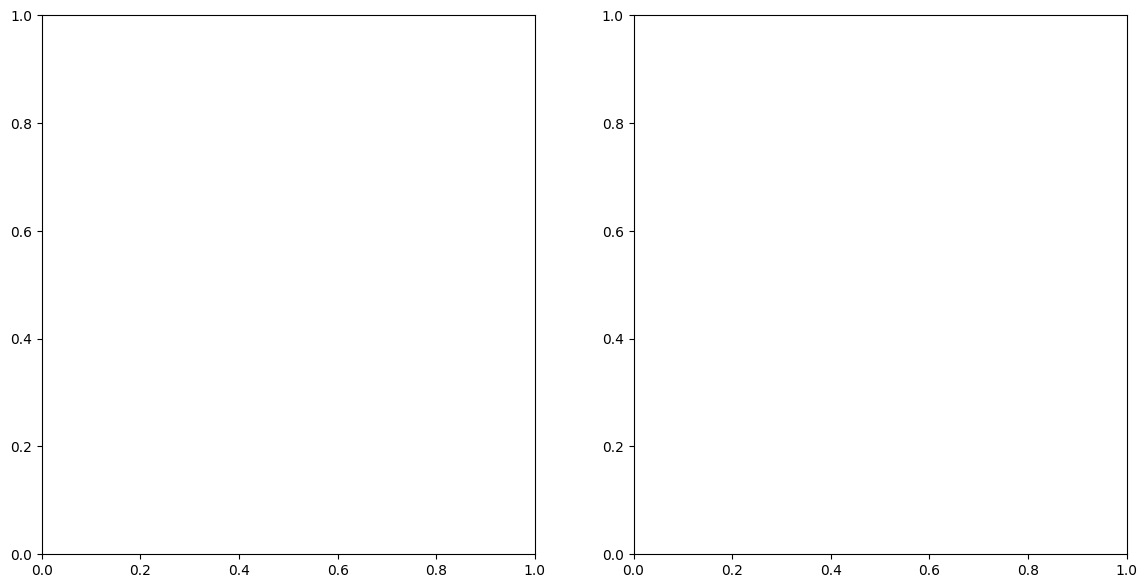

In [112]:
### Wanting to make a Multiples Map of this
fig, ax = plt.subplots(1, 2, figsize=(14,7))

## State Maps

### Kerala 

In [116]:
state_df = pd.read_csv("dravidian-mother-tongues-main-s-level.csv") 
state_df

,State,Mother tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F
0,Kerala,Malayalam,32393324,15482417,16910907,16848670,8082073,8766597,15544654,7400344,8144310
1,Kerala,Tamil,502516,258947,243569,346256,176165,170091,156260,82782,73478
2,Kerala,Telugu,35380,18214,17166,17678,9038,8640,17702,9176,8526
3,Kerala,Kannada,78067,39578,38489,49503,25000,24503,28564,14578,13986
4,Kerala,Tulu,124256,61673,62583,91037,45260,45777,33219,16413,16806
5,Kerala,Pania,15530,7477,8053,14804,7129,7675,726,348,378
6,Kerala,Irula/Irular Mozhi,3562,1752,1810,3562,1752,1810,0,0,0
7,Kerala,Coorgi/Kodagu,75,39,36,30,13,17,45,26,19
8,Kerala,Gondi,4,0,4,0,0,0,4,0,4
9,Tamil Nadu,Malayalam,718977,347788,371189,104745,51089,53656,614232,296699,317533


In [121]:
kerala_df = state_df[state_df["State"] == "Kerala"]
kerala_df

,State,Mother tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F
0,Kerala,Malayalam,32393324,15482417,16910907,16848670,8082073,8766597,15544654,7400344,8144310
1,Kerala,Tamil,502516,258947,243569,346256,176165,170091,156260,82782,73478
2,Kerala,Telugu,35380,18214,17166,17678,9038,8640,17702,9176,8526
3,Kerala,Kannada,78067,39578,38489,49503,25000,24503,28564,14578,13986
4,Kerala,Tulu,124256,61673,62583,91037,45260,45777,33219,16413,16806
5,Kerala,Pania,15530,7477,8053,14804,7129,7675,726,348,378
6,Kerala,Irula/Irular Mozhi,3562,1752,1810,3562,1752,1810,0,0,0
7,Kerala,Coorgi/Kodagu,75,39,36,30,13,17,45,26,19
8,Kerala,Gondi,4,0,4,0,0,0,4,0,4


In [123]:
tamil_nadu_df = state_df[state_df["State"] == "Tamil Nadu"]
tamil_nadu_df

,State,Mother tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F
9,Tamil Nadu,Malayalam,718977,347788,371189,104745,51089,53656,614232,296699,317533
10,Tamil Nadu,Tamil,63743847,31913539,31830308,34087554,17096202,16991352,29656293,14817337,14838956
11,Tamil Nadu,Telugu,4234216,2117945,2116271,1973842,991195,982647,2260374,1126750,1133624
12,Tamil Nadu,Kannada,1768,861,907,159,82,77,1609,779,830
13,Tamil Nadu,Tulu,33,18,15,2,1,1,31,17,14
14,Tamil Nadu,Pania,22808,11015,11793,19391,9340,10051,3417,1675,1742
15,Tamil Nadu,Irula/Irular Mozhi,11870,5850,6020,11297,5564,5733,573,286,287
16,Tamil Nadu,Coorgi/Kodagu,16939,8290,8649,2730,1378,1352,14209,6912,7297
17,Tamil Nadu,Gondi,2856581,1412226,1444355,2751694,1359001,1392693,104887,53225,51662


In [124]:
karnataka_df = state_df[state_df["State"] == "Karnataka"]
karnataka_df

,State,Mother tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F
18,Karnataka,Malayalam,745903,374572,371331,312494,155400,157094,433409,219172,214237
19,Karnataka,Tamil,2101032,1062389,1038643,328485,167600,160885,1772547,894789,877758
20,Karnataka,Telugu,3565618,1796969,1768649,1616012,808160,807852,1949606,988809,960797
21,Karnataka,Kannada,40622836,20552989,20069847,29019265,14659315,14359950,11603571,5893674,5709897
22,Karnataka,Tulu,1592915,773821,819094,987666,479086,508580,605249,294735,310514
23,Karnataka,Pania,257,116,141,247,114,133,10,2,8
24,Karnataka,Irula/Irular Mozhi,0,0,0,0,0,0,0,0,0
25,Karnataka,Coorgi/Kodagu,13630,6600,7030,693,350,343,12937,6250,6687
26,Karnataka,Gondi,1012,501,511,283,147,136,729,354,375


In [125]:
andhra_df = state_df[state_df["State"] == "Andhra Pradesh"]
andhra_df

,State,Mother tongue,Total_P,Total_M,Total_F,Rural_P,Rural_M,Rural_F,Urban_P,Urban_M,Urban_F
27,Andhra Pradesh,Malayalam,61108,29648,31460,8378,3814,4564,52730,25834,26896
28,Andhra Pradesh,Tamil,625546,313271,312275,318459,158772,159687,307087,154499,152588
29,Andhra Pradesh,Telugu,70662838,35382930,35279908,49347283,24714317,24632966,21315555,10668613,10646942
30,Andhra Pradesh,Kannada,532937,259988,272949,399006,192834,206172,133931,67154,66777
31,Andhra Pradesh,Tulu,516,263,253,31,16,15,485,247,238
32,Andhra Pradesh,Pania,257,116,141,247,114,133,10,2,8
33,Andhra Pradesh,Irula/Irular Mozhi,0,0,0,0,0,0,0,0,0
34,Andhra Pradesh,Coorgi/Kodagu,257,116,141,247,114,133,10,2,8
35,Andhra Pradesh,Gondi,1012,501,511,283,147,136,729,354,375


In [ ]:
df = pd.read_csv("glottolog_languoid.csv/languoid.csv") 
df.head() 

In [ ]:
tulu = df[df["name"] == "Tulu"]
tulu

In [ ]:
gondi = df[df["name"] == "Gondi"]
gondi

In [ ]:
# 